In [1]:
import sys

print(sys.version)
print(sys.executable)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
C:\Users\Prithvi Vinayak P\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe


# 1. Dataset Overview

This section explores the structure and basic characteristics of the processed CEEW household energy dataset.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("../output/analysis_ready_data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


C:\Users\Prithvi Vinayak P\AppData\Local\Temp\ipykernel_34324\3948629616.py:1: DtypeWarning: Columns (6: district_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../output/analysis_ready_data.csv")


In [4]:
df.head()

,hhid,enumerator_id,state,state_abbr,state_code,district,district_code,village_ward,village_ward_census_code,interview_date,...,elec_bill_per_member,expenditure_per_member,bill_share_of_expenditure_pct,people_per_bedroom,age_group,household_size_group,expenditure_group,bill_group,state_bill_rank,household_bill_rank
0,34678942,AP_7,Andhra Pradesh,AP,28,Chittoor,554,Avilala (Ct) Ward No.-0001,595740-1,2019-12-15,...,527.50,2500.0,21.10,2.0,60+,Small (1-3),Medium (5k-10k),High (700-1499),3,2739
1,34678943,AP_7,Andhra Pradesh,AP,28,Chittoor,554,Avilala (Ct) Ward No.-0001,595740-1,2019-12-15,...,263.75,750.0,35.17,4.0,18-29,Medium (4-6),Low (<5k),High (700-1499),3,2739
2,34678944,AP_7,Andhra Pradesh,AP,28,Chittoor,554,Avilala (Ct) Ward No.-0001,595740-1,2019-12-15,...,211.00,1000.0,21.10,5.0,30-44,Medium (4-6),Medium (5k-10k),High (700-1499),3,2739
3,34678946,AP_7,Andhra Pradesh,AP,28,Chittoor,554,Avilala (Ct) Ward No.-0001,595740-1,2019-12-15,...,183.33,1558.0,11.77,1.0,60+,Small (1-3),Low (<5k),Low (<300),3,13019
4,34678949,AP_7,Andhra Pradesh,AP,28,Chittoor,554,Neerpakota,595930,2019-12-16,...,263.75,1000.0,26.38,4.0,60+,Medium (4-6),Low (<5k),High (700-1499),3,2739


In [5]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 14851
Number of Columns: 341


In [6]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14851 entries, 0 to 14850
Columns: 341 entries, hhid to household_bill_rank
dtypes: bool(3), float64(269), int64(56), object(1), str(12)
memory usage: 38.3+ MB


In [7]:
# Display all column names

pd.set_option('display.max_rows', None)

print(df.columns.tolist())

['hhid', 'enumerator_id', 'state', 'state_abbr', 'state_code', 'district', 'district_code', 'village_ward', 'village_ward_census_code', 'interview_date', 'interview_start_time', 'survey_type_code', 'respondent_gender_code', 'respondent_age', 'q203_priminc_earner_who', 'q204_priminc_earner_gender', 'q205_priminc_earner_age', 'q206_priminc_earner_head_yn', 'q208_priminc_earner_edu', 'q209_edu_highest', 'q210_religion', 'caste_code', 'q212_ration_card', 'household_size', 'members_under_18', 'members_18_40', 'members_41_60', 'members_over_60', 'q215_no_members_studying', 'q216_house_pucca_kachha', 'q217_house_type', 'q218_house_no_stories', 'q219_house_stay_groundfloor_yn', 'q219_house_stay_middlefloor_yn', 'q219_house_stay_topfloor_yn', 'q219_house_stay_allfloors_yn', 'owns_house', 'q222_yrs_samehouse', 'bedrooms', 'q224_house_no_toilets', 'q225_house_no_otherrooms', 'q226_tree_shade_yn', 'q227_a_plot_area', 'q227_a_plot_unit', 'land_area_sqft', 'land_area_sqfeet_reportd_estimtd', 'q228_p

In [8]:
# Numerical summary
df.describe()

,hhid,state_code,survey_type_code,respondent_gender_code,respondent_age,q203_priminc_earner_who,q204_priminc_earner_gender,q205_priminc_earner_age,q206_priminc_earner_head_yn,q208_priminc_earner_edu,...,asset_decile_1,asset_index_2,asset_decile_2,interview_start_hour,elec_bill_per_member,expenditure_per_member,bill_share_of_expenditure_pct,people_per_bedroom,state_bill_rank,household_bill_rank
count,1.485100e+04,14851.000000,14851.000000,14851.000000,14851.000000,14851.000000,14851.000000,5447.000000,14851.000000,14851.000000,...,14851.000000,1.485100e+04,14851.000000,14851.000000,14851.000000,14851.000000,14851.000000,14851.000000,14851.000000,14851.000000
mean,8.965176e+08,18.628106,1.339236,0.283819,40.891388,1.575382,0.106188,43.519368,0.841021,4.354791,...,5.500303,2.430813e-11,5.500303,13.217763,167.132339,1816.848769,9.938287,3.058718,11.383139,7256.737257
std,1.269108e+09,9.839592,0.473466,0.450865,12.802782,0.909744,0.308089,11.179138,0.365669,2.055748,...,2.872519,1.821563e+00,2.872519,2.303471,173.541910,1292.088293,7.868846,1.693931,5.716548,4298.934158
min,3.435240e+07,2.000000,1.000000,0.000000,18.000000,1.000000,0.000000,18.000000,0.000000,1.000000,...,1.000000,-2.784152e+00,1.000000,0.000000,5.930000,153.850000,0.360000,0.330000,1.000000,1.000000
25%,3.436633e+08,9.000000,1.000000,0.000000,31.000000,1.000000,0.000000,35.000000,1.000000,3.000000,...,3.000000,-1.306792e+00,3.000000,12.000000,53.330000,1000.000000,4.170000,2.000000,7.000000,3431.000000
50%,3.456062e+08,20.000000,1.000000,0.000000,40.000000,1.000000,0.000000,43.000000,1.000000,5.000000,...,6.000000,-1.227276e-01,6.000000,13.000000,116.670000,1500.000000,7.940000,2.500000,11.000000,7323.000000
75%,3.544271e+08,27.000000,2.000000,1.000000,50.000000,2.000000,0.000000,50.000000,1.000000,6.000000,...,8.000000,9.571477e-01,8.000000,15.000000,214.290000,2250.000000,13.890000,4.000000,16.000000,10718.000000
max,3.512299e+09,36.000000,2.000000,1.000000,100.000000,6.000000,1.000000,100.000000,1.000000,8.000000,...,10.000000,6.215074e+00,10.000000,22.000000,2400.000000,22000.000000,96.280000,18.000000,21.000000,14754.000000


In [9]:
# Categorical summary
df.describe(include=['object'])

C:\Users\Prithvi Vinayak P\AppData\Local\Temp\ipykernel_34324\3932823055.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=['object'])


,enumerator_id,state,state_abbr,district,district_code,village_ward,village_ward_census_code,interview_date,interview_start_time,age_group,household_size_group,expenditure_group,bill_group
count,14851,14851,14851,14851,14851,14851,14851,14851,14851,14851,14851,14851,14851
unique,224,21,21,151,153,1806,1806,117,648,4,3,4,4
top,UP_14,Uttar Pradesh,UP,Raigarh,507,Noida (Ct) Ward No.-0001,120227-1,2019-12-06,12:40 PM,30-44,Medium (4-6),Medium (5k-10k),High (700-1499)
freq,326,1548,1548,193,110,48,48,373,114,6078,9296,7771,4721


# Section 2 – Data Quality Analysis

In [10]:
# Check dataset dimensions

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 14851
Number of Columns: 341


In [11]:
# Missing Value Analysis

# Calculate missing values in each column

missing_values = df.isnull().sum()

# Calculate missing percentage

missing_percentage = (missing_values / len(df)) * 100

# Create a missing-value summary

missing_summary = pd.DataFrame({
    "Missing_Values": missing_values,
    "Missing_Percentage": missing_percentage
})

# Display only columns containing missing values

missing_summary = missing_summary[
    missing_summary["Missing_Values"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_summary

,Missing_Values,Missing_Percentage
q479_water_pump_bee_star,14112,95.023904
q608_e_if_trust_increase,13709,92.310282
q608_d_ifprep_elec_theft,13704,92.276614
q608_c_ifprep_wrong_bill,13686,92.155410
q608_b_ifprep_elec_bill_change,13671,92.054407
q608_a_ifprep_control_elec_exp,13639,91.838933
q606_prepaid_meter_yn,13246,89.192647
q426_air_coolers_mostused_brand,13226,89.057976
q478_water_pump_yrs,13206,88.923305
q406_noled_reason,13189,88.808834


In [12]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 0


In [13]:
# Check data types

df.dtypes

hhid                                   int64
enumerator_id                            str
state                                    str
state_abbr                               str
state_code                             int64
district                                 str
district_code                         object
village_ward                             str
village_ward_census_code                 str
interview_date                           str
interview_start_time                     str
survey_type_code                       int64
respondent_gender_code                 int64
respondent_age                         int64
q203_priminc_earner_who                int64
q204_priminc_earner_gender             int64
q205_priminc_earner_age              float64
q206_priminc_earner_head_yn            int64
q208_priminc_earner_edu                int64
q209_edu_highest                       int64
q210_religion                          int64
caste_code                           float64
q212_ratio

In [14]:
# Get a complete data-type summary

# Count columns by data type

df.dtypes.value_counts()

float64    269
int64       56
str         12
bool         3
object       1
Name: count, dtype: int64

In [15]:
# Display the number of numerical and categorical columns

print("Numerical columns:", df.select_dtypes(include=["int64", "float64"]).shape[1])

print("Categorical columns:", df.select_dtypes(include=["object", "str", "category"]).shape[1])

Numerical columns: 325
Categorical columns: 13


In [16]:
# Check whether any columns have unusual data types

# Identify date and time related columns

date_time_columns = [
    col for col in df.columns
    if "date" in col.lower() or "time" in col.lower()
]

df[date_time_columns].head()

,interview_date,interview_start_time,q470_fridge_off_time,q517_c_firewood_collect_time,q532_a_prim_cook_arrange_time,q610_e_bill_date
0,2019-12-15,11:25 AM,NaN,NaN,NaN,12.0
1,2019-12-15,12:39 PM,1.0,NaN,NaN,6.0
2,2019-12-15,1:24 PM,1.0,NaN,NaN,6.0
3,2019-12-15,2:29 PM,NaN,NaN,0.0,4.0
4,2019-12-16,10:30 AM,NaN,NaN,NaN,10.0


In [17]:
# Check whether interview dates are valid

# Convert interview dates to datetime without modifying df

parsed_dates = pd.to_datetime(
    df["interview_date"],
    errors="coerce"
)

# Check invalid or missing dates

print("Invalid or Missing Interview Dates:",
      parsed_dates.isna().sum())

# Check interview date range

print("Earliest Interview Date:", parsed_dates.min())
print("Latest Interview Date:", parsed_dates.max())

Invalid or Missing Interview Dates: 0
Earliest Interview Date: 2018-12-25 00:00:00
Latest Interview Date: 2020-12-15 00:00:00


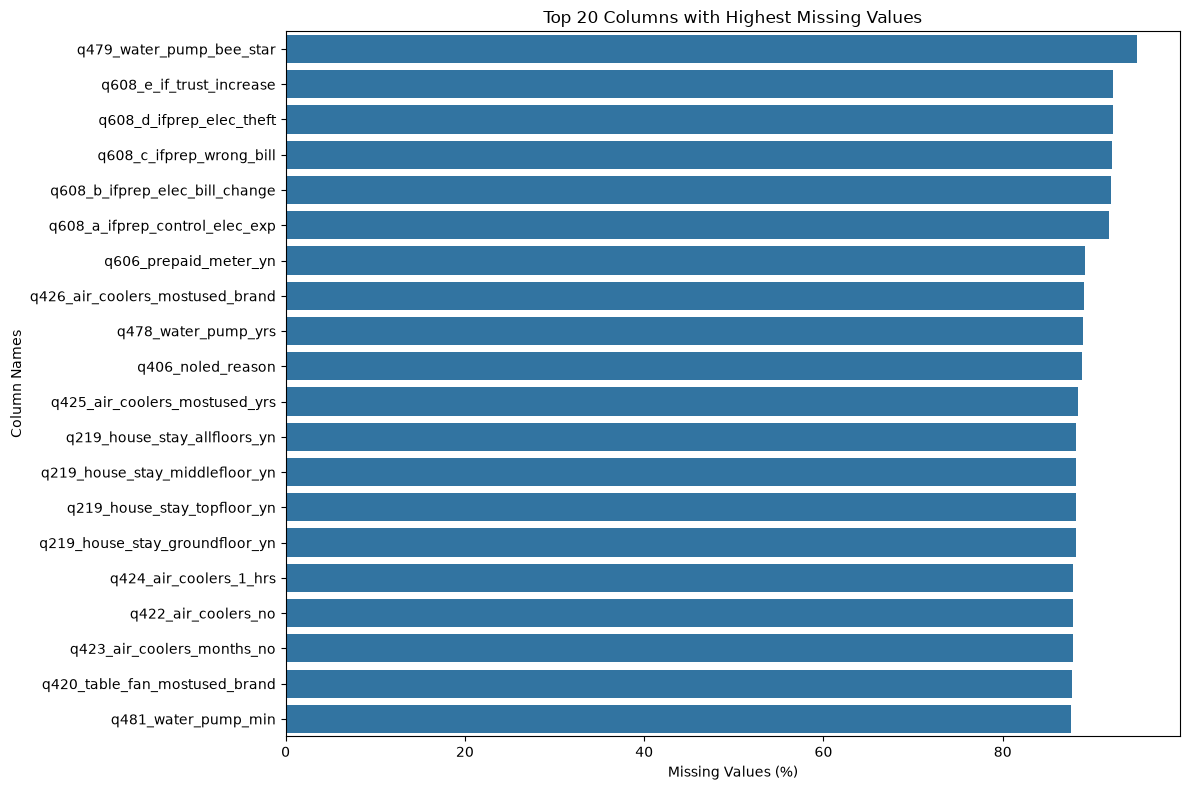

In [18]:
# Visualize missing values

# Visualize the top 20 columns with missing values

top_missing = missing_summary.head(20)

plt.figure(figsize=(12, 8))

sns.barplot(
    x="Missing_Percentage",
    y=top_missing.index,
    data=top_missing
)

plt.title("Top 20 Columns with Highest Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column Names")

plt.tight_layout()
plt.show()

In [19]:
# One final check: Missing-value summary

# Overall missing-value statistics

total_cells = df.size
total_missing = df.isnull().sum().sum()
total_present = total_cells - total_missing

missing_percentage = (total_missing / total_cells) * 100

print("Total Data Cells:", total_cells)
print("Total Missing Values:", total_missing)
print("Total Present Values:", total_present)
print("Overall Missing Percentage:", round(missing_percentage, 2), "%")

Total Data Cells: 5064191
Total Missing Values: 1303778
Total Present Values: 3760413
Overall Missing Percentage: 25.75 %


### Key Findings – Data Quality Analysis

1. The processed dataset contains 14,851 rows and 341 columns.
2. A total of 258 columns contain missing values, while 83 columns have no missing values.
3. The dataset contains 1,303,778 missing cells, representing 25.75% of all data cells.
4. Approximately 74.25% of the dataset contains present values.
5. No exact duplicate rows were identified.
6. The interview_date column contains no invalid or missing dates.
7. Interview dates range from 25 December 2018 to 15 December 2020.
8. Missing values vary significantly across survey questions. Some questions have very high missing percentages, which may be related to survey skip logic or conditional questions.

No additional missing-value treatment was performed during this analysis.

# 3. Descriptive Statistics

This section explores the statistical characteristics of numerical variables in the dataset using measures such as mean, median, standard deviation, minimum, maximum and quartiles.

In [20]:
# Generate descriptive statistics for numerical columns
df.describe()

,hhid,state_code,survey_type_code,respondent_gender_code,respondent_age,q203_priminc_earner_who,q204_priminc_earner_gender,q205_priminc_earner_age,q206_priminc_earner_head_yn,q208_priminc_earner_edu,...,asset_decile_1,asset_index_2,asset_decile_2,interview_start_hour,elec_bill_per_member,expenditure_per_member,bill_share_of_expenditure_pct,people_per_bedroom,state_bill_rank,household_bill_rank
count,1.485100e+04,14851.000000,14851.000000,14851.000000,14851.000000,14851.000000,14851.000000,5447.000000,14851.000000,14851.000000,...,14851.000000,1.485100e+04,14851.000000,14851.000000,14851.000000,14851.000000,14851.000000,14851.000000,14851.000000,14851.000000
mean,8.965176e+08,18.628106,1.339236,0.283819,40.891388,1.575382,0.106188,43.519368,0.841021,4.354791,...,5.500303,2.430813e-11,5.500303,13.217763,167.132339,1816.848769,9.938287,3.058718,11.383139,7256.737257
std,1.269108e+09,9.839592,0.473466,0.450865,12.802782,0.909744,0.308089,11.179138,0.365669,2.055748,...,2.872519,1.821563e+00,2.872519,2.303471,173.541910,1292.088293,7.868846,1.693931,5.716548,4298.934158
min,3.435240e+07,2.000000,1.000000,0.000000,18.000000,1.000000,0.000000,18.000000,0.000000,1.000000,...,1.000000,-2.784152e+00,1.000000,0.000000,5.930000,153.850000,0.360000,0.330000,1.000000,1.000000
25%,3.436633e+08,9.000000,1.000000,0.000000,31.000000,1.000000,0.000000,35.000000,1.000000,3.000000,...,3.000000,-1.306792e+00,3.000000,12.000000,53.330000,1000.000000,4.170000,2.000000,7.000000,3431.000000
50%,3.456062e+08,20.000000,1.000000,0.000000,40.000000,1.000000,0.000000,43.000000,1.000000,5.000000,...,6.000000,-1.227276e-01,6.000000,13.000000,116.670000,1500.000000,7.940000,2.500000,11.000000,7323.000000
75%,3.544271e+08,27.000000,2.000000,1.000000,50.000000,2.000000,0.000000,50.000000,1.000000,6.000000,...,8.000000,9.571477e-01,8.000000,15.000000,214.290000,2250.000000,13.890000,4.000000,16.000000,10718.000000
max,3.512299e+09,36.000000,2.000000,1.000000,100.000000,6.000000,1.000000,100.000000,1.000000,8.000000,...,10.000000,6.215074e+00,10.000000,22.000000,2400.000000,22000.000000,96.280000,18.000000,21.000000,14754.000000


In [21]:
# Descriptive statistics for categorical columns

# Generate descriptive statistics for categorical columns
df.describe(include=["object", "str"])

,enumerator_id,state,state_abbr,district,district_code,village_ward,village_ward_census_code,interview_date,interview_start_time,age_group,household_size_group,expenditure_group,bill_group
count,14851,14851,14851,14851,14851,14851,14851,14851,14851,14851,14851,14851,14851
unique,224,21,21,151,153,1806,1806,117,648,4,3,4,4
top,UP_14,Uttar Pradesh,UP,Raigarh,507,Noida (Ct) Ward No.-0001,120227-1,2019-12-06,12:40 PM,30-44,Medium (4-6),Medium (5k-10k),High (700-1499)
freq,326,1548,1548,193,110,48,48,373,114,6078,9296,7771,4721


### Categorical Descriptive Statistics – Key Findings

1. The dataset contains 13 categorical columns.
2. There are 21 unique states and 151 unique districts.
3. Uttar Pradesh is the most frequently represented state, with 1,548 records.
4. Raigarh is the most frequently represented district, with 193 records.
5. Medium household size (4–6 members) is the most common group, with 9,296 records.
6. Medium expenditure (5k–10k) is the most common expenditure group, with 7,771 records.
7. High electricity bill group (700–1499) is the most frequent bill category, with 4,721 records.
8. The dataset contains 117 unique interview dates and 224 unique enumerator IDs.

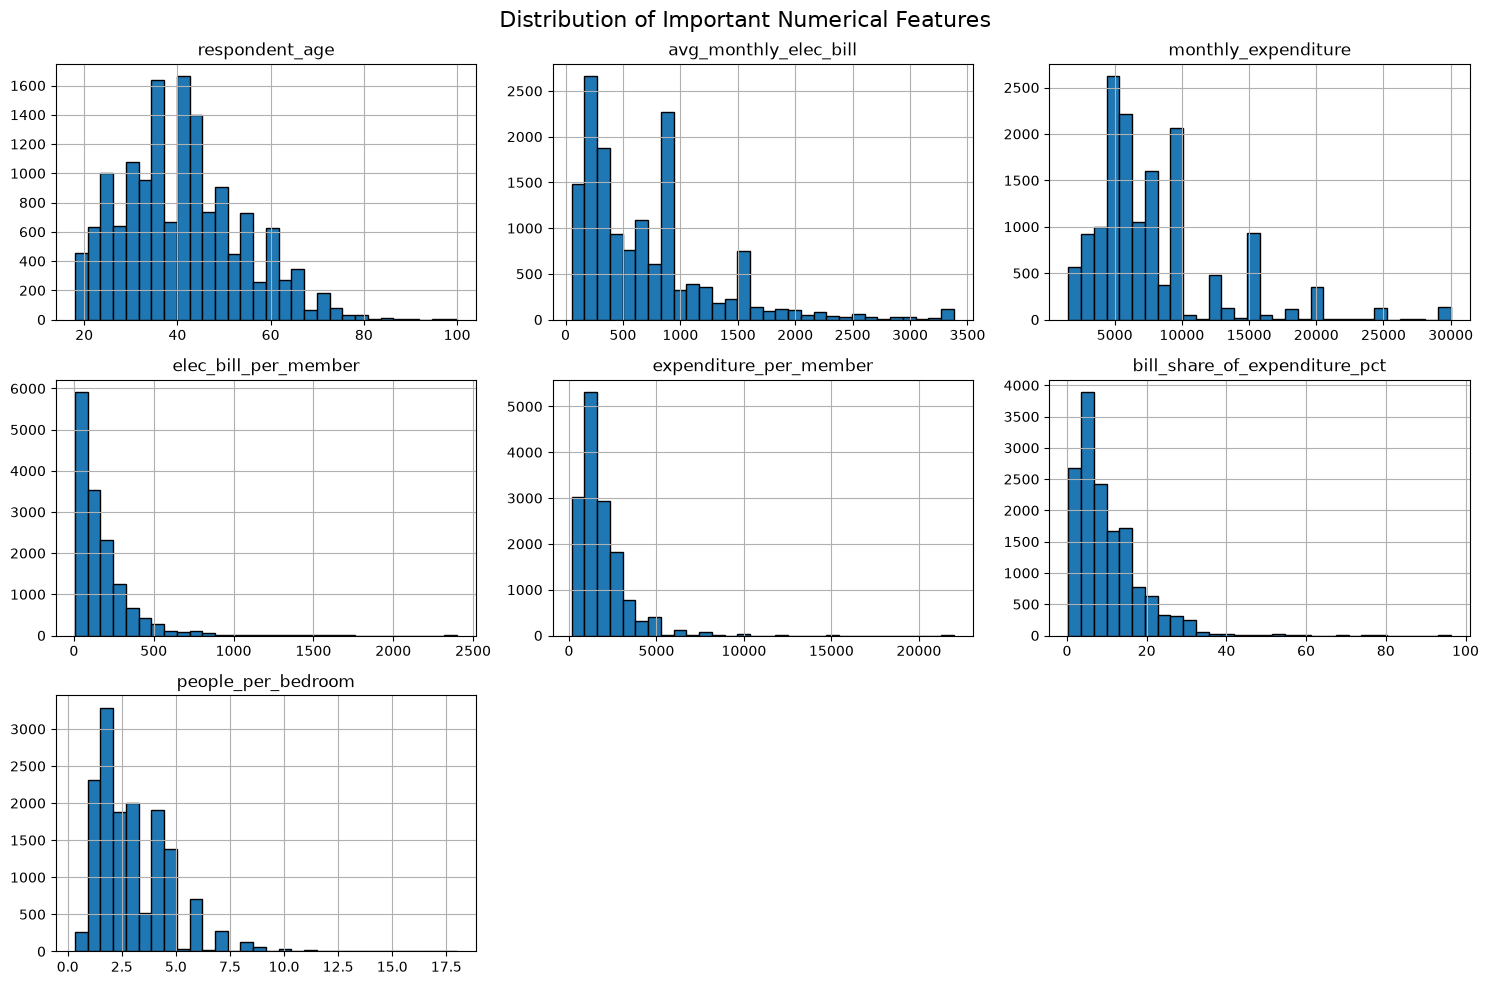

In [22]:
# Numerical feature distribution

# Select important numerical columns
selected_columns = [
    "respondent_age",
    "avg_monthly_elec_bill",
    "monthly_expenditure",
    "elec_bill_per_member",
    "expenditure_per_member",
    "bill_share_of_expenditure_pct",
    "people_per_bedroom"
]

# Plot histograms
df[selected_columns].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Important Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

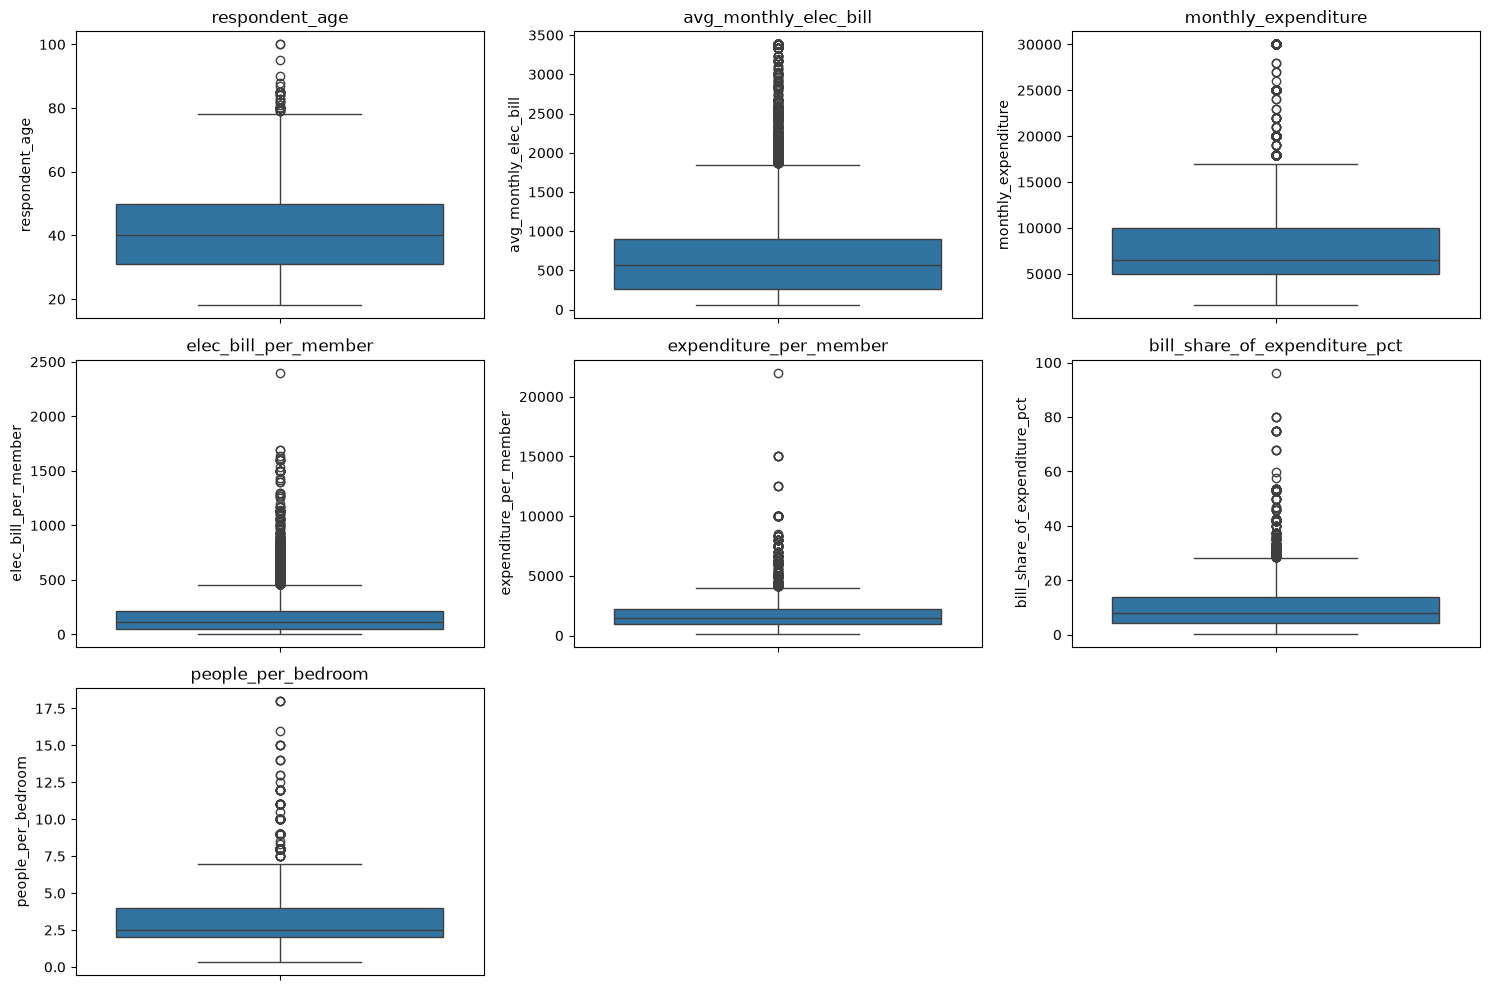

In [23]:
# Boxplots
# Boxplots will help us identify 
# potential outliers and understand the spread of the numerical variables.

# Create boxplots for important numerical features
plt.figure(figsize=(15, 10))

for i, column in enumerate(selected_columns, 1):
    plt.subplot(3, 3, i)

    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [24]:
# Understand the boxplot results

# Before deciding whether any outliers need treatment, 
# let's calculate the number of potential outliers in each feature using the IQR method.

#The IQR method identifies values outside these limits:

'''{Lower Limit}=Q1-1.5(IQR)

{Upper Limit}=Q3+1.5(IQR)'''

# Identify potential outliers using the IQR method

outlier_results = []

for column in selected_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    outlier_results.append({
        "Feature": column,
        "Lower_Limit": lower_limit,
        "Upper_Limit": upper_limit,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": (len(outliers) / len(df)) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary.round(2)


,Feature,Lower_Limit,Upper_Limit,Outlier_Count,Outlier_Percentage
0,respondent_age,2.50,78.50,51,0.34
1,avg_monthly_elec_bill,-683.33,1850.00,672,4.52
2,monthly_expenditure,-2500.00,17500.00,746,5.02
3,elec_bill_per_member,-188.11,455.73,881,5.93
4,expenditure_per_member,-875.00,4125.00,762,5.13
5,bill_share_of_expenditure_pct,-10.41,28.47,447,3.01
6,people_per_bedroom,-1.00,7.00,271,1.82


### Boxplot and Outlier Analysis – Key Findings

1. Boxplots were generated for seven important numerical features.
2. Potential outliers were identified using the Interquartile Range (IQR) method.
3. The highest outlier percentage was observed in elec_bill_per_member (5.93%).
4. Monthly expenditure had 746 potential outliers (5.02%).
5. Average monthly electricity bill had 672 potential outliers (4.52%).
6. Respondent age had the lowest outlier percentage (0.34%).
7. Potential outliers may represent genuine household observations and should not automatically be removed.
8. Further investigation is required before applying any outlier treatment.

In [25]:
# Univariate Analysis

# Our first analysis will be the distribution of households across states.

# Count households in each state
state_distribution = df["state"].value_counts()

state_distribution

state
Uttar Pradesh       1548
Maharashtra         1409
Bihar               1346
West Bengal          980
Rajasthan            973
Tamil Nadu           969
Madhya Pradesh       964
Gujarat              798
Karnataka            788
Odisha               586
Andhra Pradesh       498
Telangana            493
Assam                399
Punjab               397
Delhi                395
Chhattisgarh         386
Jharkhand            386
Kerala               385
Himachal Pradesh     384
Uttarakhand          384
Haryana              383
Name: count, dtype: int64

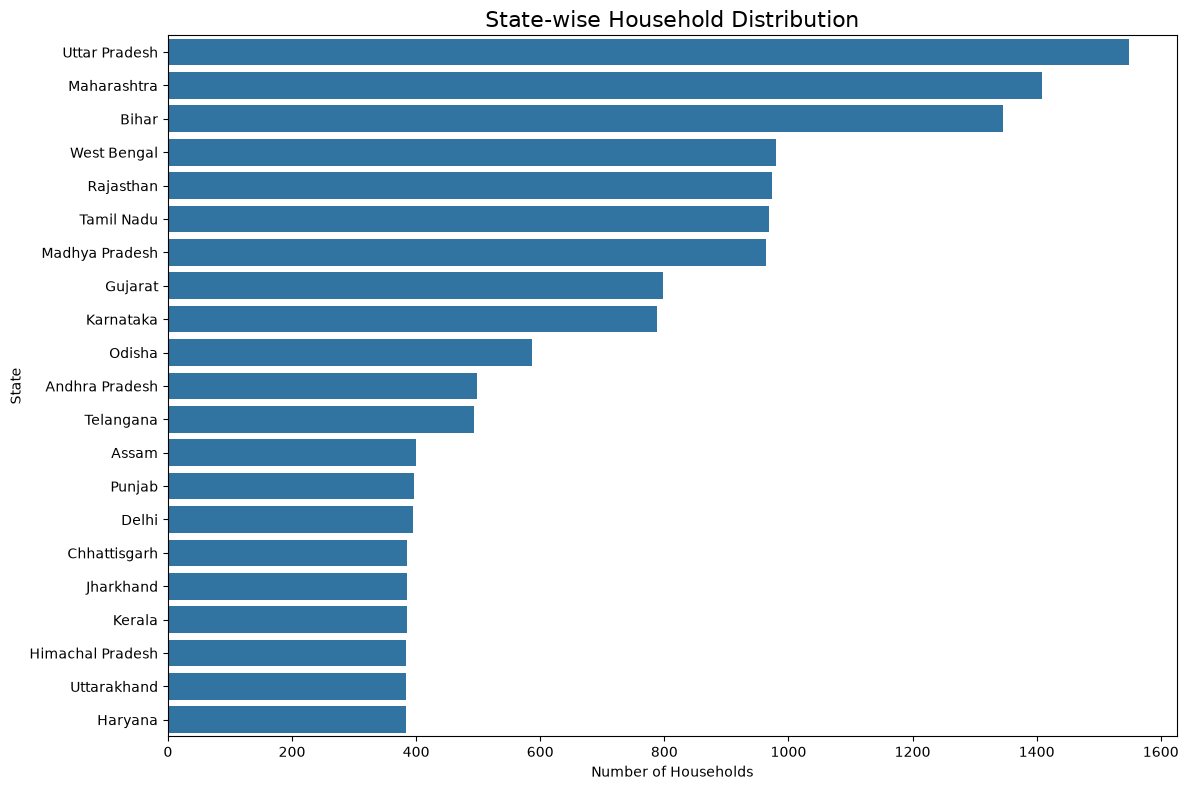

In [26]:
# Visualize state-wise household distribution

plt.figure(figsize=(12, 8))

sns.barplot(
    x=state_distribution.values,
    y=state_distribution.index
)

plt.title("State-wise Household Distribution", fontsize=16)
plt.xlabel("Number of Households")
plt.ylabel("State")

plt.tight_layout()
plt.show()

### State-wise Household Distribution – Key Findings

1. The dataset contains 14,851 household records across 21 states.
2. Uttar Pradesh has the highest representation with 1,548 records.
3. Maharashtra has the second-highest representation with 1,409 records.
4. Bihar ranks third with 1,346 records.
5. Haryana has the lowest representation with 383 records.
6. Kerala contributes 385 household records.
7. The number of records varies across states.

In [27]:
# Household Size Distribution

# examines how many households belong to each household-size category.

# Count households in each household size group
household_size_distribution = df["household_size_group"].value_counts()

household_size_distribution

household_size_group
Medium (4-6)    9296
Small (1-3)     2977
Large (7+)      2578
Name: count, dtype: int64

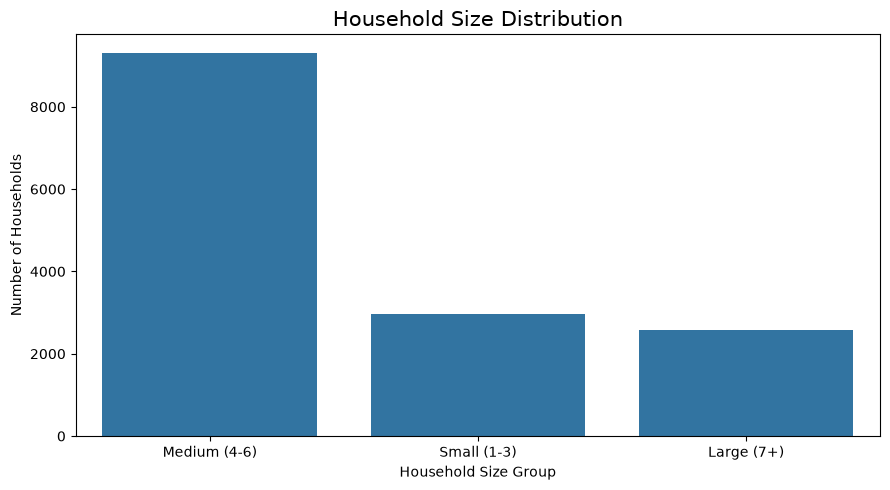

In [28]:
# Visualize household-size distribution


plt.figure(figsize=(9, 5))

sns.barplot(
    x=household_size_distribution.index,
    y=household_size_distribution.values
)

plt.title("Household Size Distribution", fontsize=15)
plt.xlabel("Household Size Group")
plt.ylabel("Number of Households")

plt.tight_layout()
plt.show()

### Household Size Distribution – Key Findings

1. The dataset contains three household-size categories.
2. Medium households (4–6 members) are the most common, with 9,296 records (62.59%).
3. Small households (1–3 members) account for 2,977 records (20.05%).
4. Large households (7+ members) account for 2,578 records (17.36%).
5. Medium-sized households represent the majority of records in the dataset.

In [29]:
# Monthly Expenditure Group Distribution.

# Count households in each expenditure group
expenditure_distribution = df["expenditure_group"].value_counts()

expenditure_distribution

expenditure_group
Medium (5k-10k)     7771
High (10k-20k)      3830
Low (<5k)           2618
Very high (20k+)     632
Name: count, dtype: int64

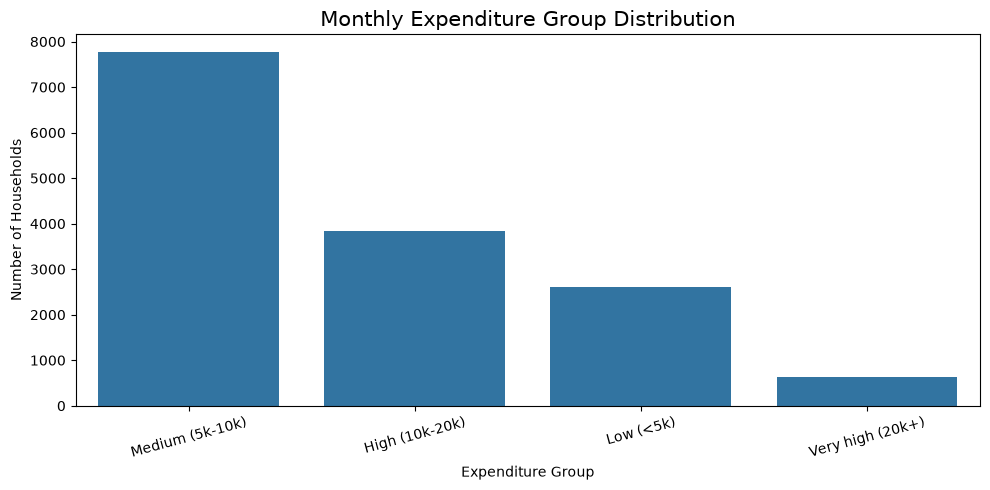

In [30]:
# Visualize monthly expenditure group distribution

plt.figure(figsize=(10, 5))

sns.barplot(
    x=expenditure_distribution.index,
    y=expenditure_distribution.values
)

plt.title("Monthly Expenditure Group Distribution", fontsize=15)
plt.xlabel("Expenditure Group")
plt.ylabel("Number of Households")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### Monthly Expenditure Distribution – Key Findings

1. The dataset contains four monthly expenditure categories.
2. Medium expenditure (₹5,000–₹10,000) is the most common category, with 7,771 households (52.33%).
3. High expenditure (₹10,000–₹20,000) accounts for 3,830 households (25.79%).
4. Low expenditure (below ₹5,000) accounts for 2,618 households (17.63%).
5. Very high expenditure (₹20,000+) is the least common category, with 632 households (4.26%).
6. More than half of the household records belong to the medium expenditure category.

In [31]:
# Electricity Bill Group Distribution

# analyse how households are distributed across different electricity bill categories.

# Count households in each electricity bill group
bill_distribution = df["bill_group"].value_counts()

bill_distribution

bill_group
High (700-1499)      4721
Low (<300)           4297
Medium (300-699)     4145
Very high (1500+)    1688
Name: count, dtype: int64

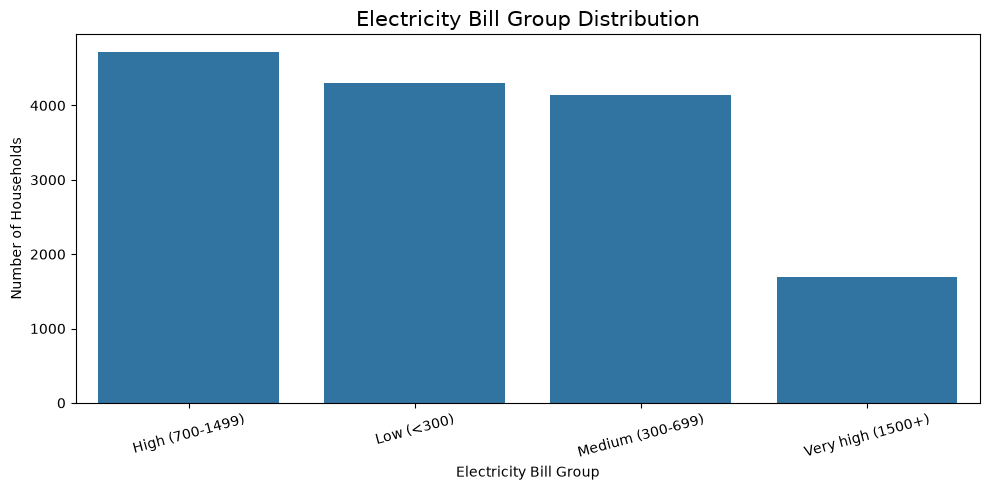

In [32]:
# Visualize electricity bill group distribution

plt.figure(figsize=(10, 5))

sns.barplot(
    x=bill_distribution.index,
    y=bill_distribution.values
)

plt.title("Electricity Bill Group Distribution", fontsize=15)
plt.xlabel("Electricity Bill Group")
plt.ylabel("Number of Households")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### Electricity Bill Group Distribution – Key Findings

1. The dataset contains four electricity bill categories.
2. High bill group (₹700–₹1,499) has the highest representation, with 4,721 households (31.79%).
3. Low bill group (below ₹300) contains 4,297 households (28.93%).
4. Medium bill group (₹300–₹699) contains 4,145 households (27.91%).
5. Very high bill group (₹1,500+) has the lowest representation, with 1,688 households (11.37%).
6. The electricity bill distribution is spread across all four categories.

In [33]:
# Age Group Distribution

# Count respondents in each age group
age_group_distribution = df["age_group"].value_counts()

age_group_distribution

age_group
30-44    6078
45-59    4237
18-29    2969
60+      1567
Name: count, dtype: int64

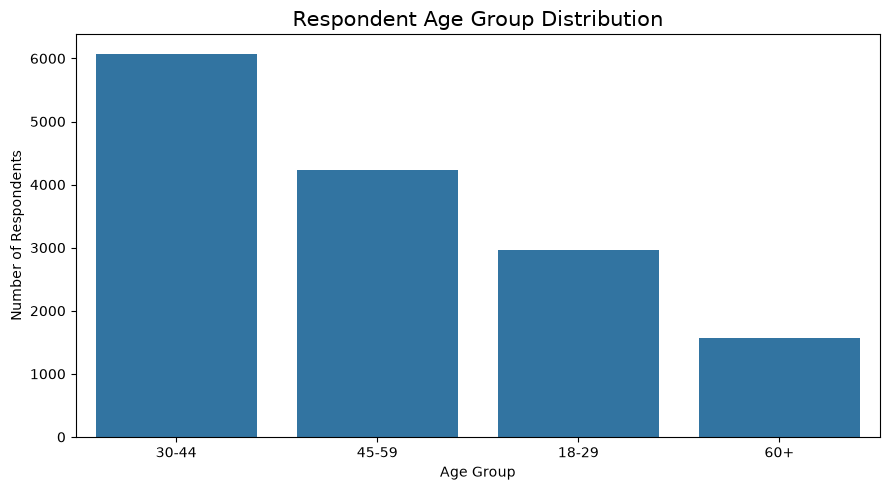

In [34]:
# Visualize age-group distribution

plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_group_distribution.index,
    y=age_group_distribution.values
)

plt.title("Respondent Age Group Distribution", fontsize=15)
plt.xlabel("Age Group")
plt.ylabel("Number of Respondents")

plt.tight_layout()
plt.show()

### Age Group Distribution – Key Findings

1. The dataset contains four respondent age groups.
2. The 30–44 age group has the highest representation, with 6,078 respondents (40.93%).
3. The 45–59 age group contains 4,237 respondents (28.53%).
4. The 18–29 age group contains 2,969 respondents (19.99%).
5. The 60+ age group has the lowest representation, with 1,567 respondents (10.55%).
6. Respondents aged 30–44 represent the largest age category.

In [35]:
# District-wise Household Distribution

# identify the districts with the highest number of household records.

# Since there are 151 unique districts, 
# we'll initially examine the top 10 districts rather than displaying all 151.

# Find the top 10 districts by household count

district_distribution = df["district"].value_counts().head(10)

district_distribution

district
Raigarh            193
Gondiya            110
Mumbai Suburban    109
Mahesana           108
Aurangabad         108
Gurdaspur          107
Morigaon           106
Mumbai             106
West Godavari      105
Darjiling          105
Name: count, dtype: int64

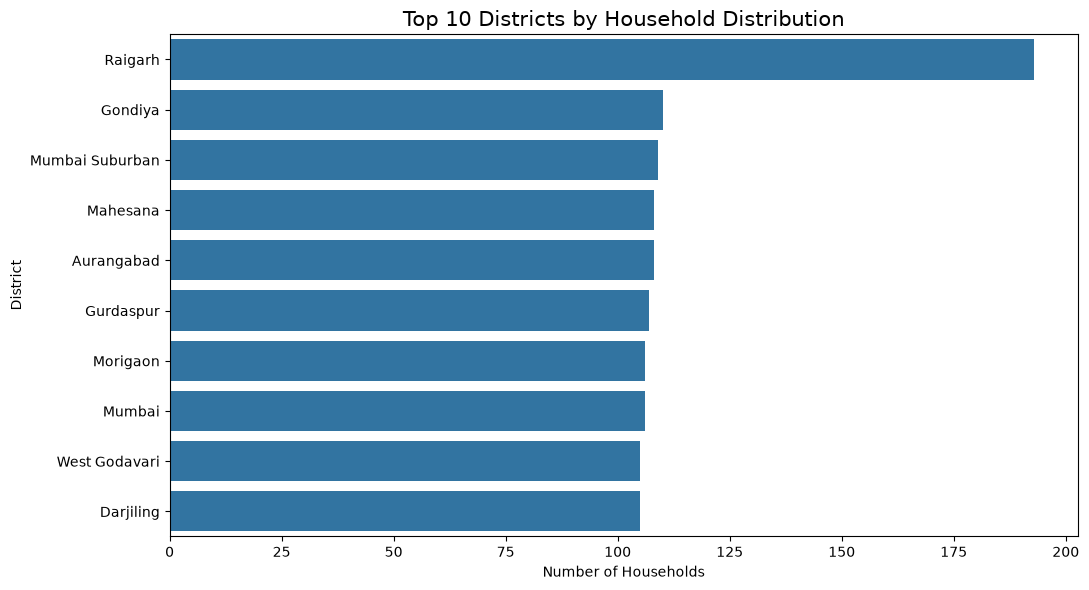

In [36]:
# Visualize top 10 districts by household count

plt.figure(figsize=(11, 6))

sns.barplot(
    x=district_distribution.values,
    y=district_distribution.index
)

plt.title("Top 10 Districts by Household Distribution", fontsize=15)
plt.xlabel("Number of Households")
plt.ylabel("District")

plt.tight_layout()
plt.show()

### District-wise Household Distribution – Key Findings

1. The dataset contains 151 unique districts.
2. Raigarh has the highest representation among the districts, with 193 household records.
3. Gondiya ranks second with 110 records.
4. Mumbai Suburban ranks third with 109 records.
5. Mahesana and Aurangabad have 108 records each.
6. The top 10 districts have household counts ranging from 105 to 193.

In [37]:
# Interview Year Distribution

# examine how the household surveys are distributed across different years.

# Our dataset contains interview dates ranging from December 2018 to December 2020.
#  We'll identify how many household interviews were conducted in each year.

# Convert interview_date into datetime format
df["interview_date"] = pd.to_datetime(df["interview_date"])

# Extract interview year
df["interview_year"] = df["interview_date"].dt.year

# Count interviews by year
year_distribution = df["interview_year"].value_counts().sort_index()

year_distribution

C:\Users\Prithvi Vinayak P\AppData\Local\Temp\ipykernel_34324\3576196051.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["interview_year"] = df["interview_date"].dt.year


interview_year
2018       1
2019    8378
2020    6472
Name: count, dtype: int64

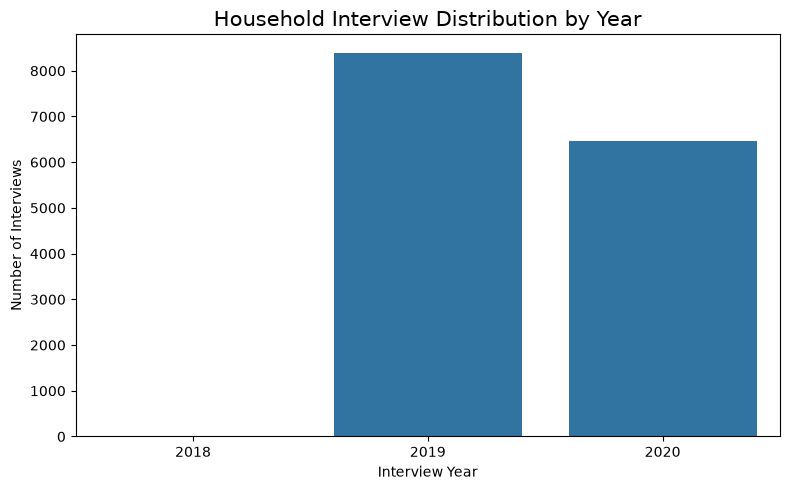

In [38]:
# Visualize interview-year distribution

plt.figure(figsize=(8, 5))

sns.barplot(
    x=year_distribution.index.astype(str),
    y=year_distribution.values
)

plt.title("Household Interview Distribution by Year", fontsize=15)
plt.xlabel("Interview Year")
plt.ylabel("Number of Interviews")

plt.tight_layout()
plt.show()

### Interview Year Distribution – Key Findings

1. The dataset contains household interviews from 2018, 2019 and 2020.
2. 2019 has the highest number of interviews, with 8,378 records (56.42%).
3. 2020 contains 6,472 records (43.58%).
4. Only one interview record belongs to 2018.
5. The majority of household interviews were conducted during 2019 and 2020.
6. These dates represent the survey collection period, not continuous electricity consumption measurements.

In [39]:
# Interview Month Distribution

# examine which months have the highest number of household interviews.

# This can help us understand the monthly pattern of survey data collection.

# Extract interview month
df["interview_month"] = df["interview_date"].dt.month_name()

# Count interviews by month
month_distribution = df["interview_date"].dt.month.value_counts().sort_index()

# Convert month numbers into month names
month_distribution.index = pd.to_datetime(
    month_distribution.index, format="%m"
).month_name()

month_distribution

C:\Users\Prithvi Vinayak P\AppData\Local\Temp\ipykernel_34324\1510128598.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["interview_month"] = df["interview_date"].dt.month_name()


interview_date
January     4188
February    1984
March        300
November     241
December    8138
Name: count, dtype: int64

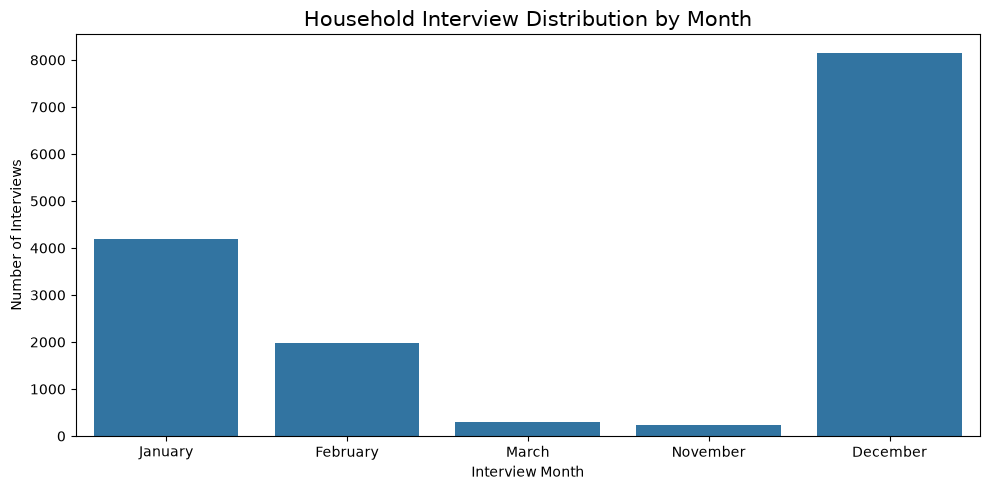

In [40]:
# Visualize interview-month distribution

plt.figure(figsize=(10, 5))

sns.barplot(
    x=month_distribution.index,
    y=month_distribution.values
)

plt.title("Household Interview Distribution by Month", fontsize=15)
plt.xlabel("Interview Month")
plt.ylabel("Number of Interviews")

plt.tight_layout()
plt.show()

### Interview Month Distribution – Key Findings

1. The dataset contains 14,851 household interview records.
2. December has the highest number of interviews, with 8,138 records (54.80%).
3. January has 4,188 interviews (28.20%).
4. February has 1,984 interviews (13.36%).
5. March and November have relatively fewer interviews.
6. No interviews are recorded between April and October.
7. Survey collection was concentrated between November and March, particularly in December.

In [41]:
# Interview Start Hour Distribution

# Count interviews by starting hour
interview_hour_distribution = df["interview_start_hour"].value_counts().sort_index()

interview_hour_distribution

interview_start_hour
0        1
3        1
7        3
8      171
9      504
10    1159
11    1786
12    2231
13    2356
14    2223
15    1862
16    1340
17     781
18     285
19     130
20      15
21       2
22       1
Name: count, dtype: int64

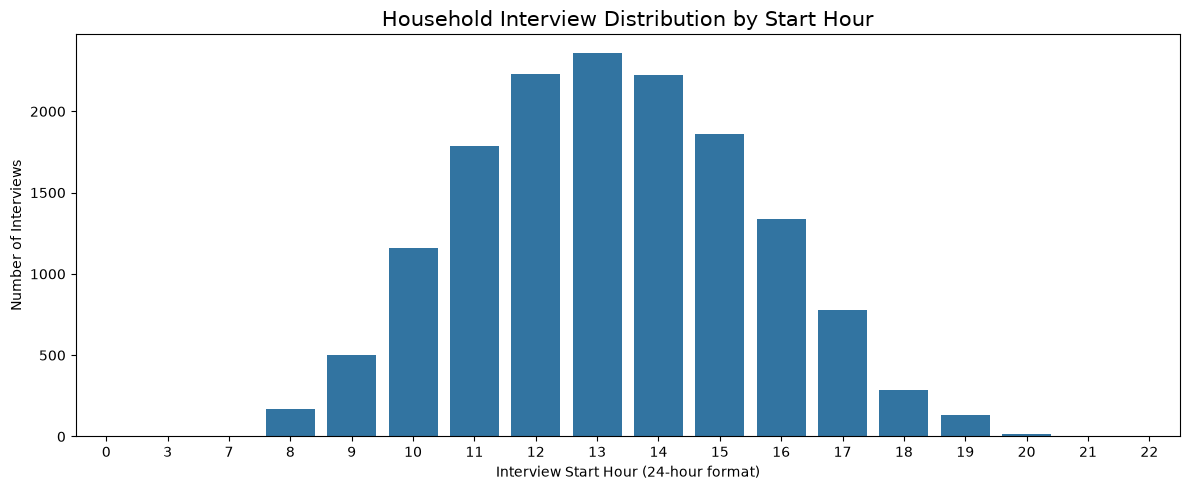

In [42]:
# Visualize interview start-hour distribution

plt.figure(figsize=(12, 5))

sns.barplot(
    x=interview_hour_distribution.index,
    y=interview_hour_distribution.values
)

plt.title("Household Interview Distribution by Start Hour", fontsize=15)
plt.xlabel("Interview Start Hour (24-hour format)")
plt.ylabel("Number of Interviews")

plt.tight_layout()
plt.show()

### Interview Start Hour Distribution – Key Findings

1. The highest number of interviews started at 13:00 (1 PM), with 2,356 records.
2. The second-highest number of interviews started at 12:00 (noon), with 2,231 records.
3. Most interviews were conducted between 10:00 and 16:00.
4. Interview frequency decreased considerably after 17:00.
5. A small number of records were observed at unusual hours, including 00:00 and 03:00.
6. These unusual time records should be checked against the original interview_start_time column.

# Section 5 – Bivariate Analysis

In [43]:
# Household Size vs Average Electricity Bill

# Calculate average electricity bill by household size

household_bill_analysis = df.groupby(
    "household_size_group"
)["avg_monthly_elec_bill"].agg(
    ["count", "mean", "median"]
).round(2)

household_bill_analysis

,count,mean,median
household_size_group,,,
Large (7+),2578,731.74,566.67
Medium (4-6),9296,702.18,566.67
Small (1-3),2977,673.81,550.00


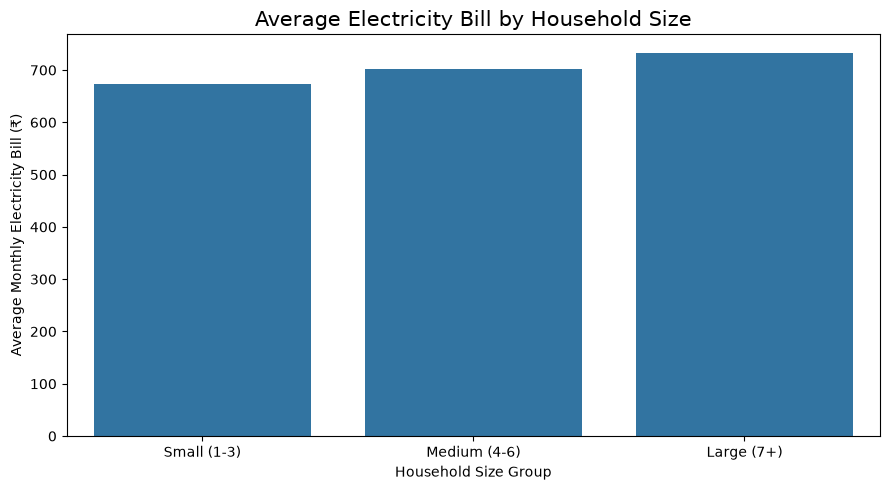

In [44]:
# Visualize household size vs electricity bill

# Visualize average electricity bill by household size

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="household_size_group",
    y="avg_monthly_elec_bill",
    estimator="mean",
    errorbar=None
)

plt.title("Average Electricity Bill by Household Size", fontsize=15)
plt.xlabel("Household Size Group")
plt.ylabel("Average Monthly Electricity Bill (₹)")

plt.tight_layout()
plt.show()

### Household Size vs Average Electricity Bill – Key Findings

1. Large households (7+) have the highest average electricity bill at ₹731.74.
2. Medium households (4–6) have an average electricity bill of ₹702.18.
3. Small households (1–3) have the lowest average electricity bill at ₹673.81.
4. Average electricity bills increase across the small, medium and large household categories.
5. The results indicate an association between household size and average electricity bills, but do not establish causation.

In [45]:
# Monthly Expenditure vs Average Electricity Bill

# to investigate whether households with higher monthly expenditure 
# also tend to have higher electricity bills.

# Calculate average electricity bill by expenditure group

expenditure_bill_analysis = df.groupby(
    "expenditure_group"
)["avg_monthly_elec_bill"].agg(
    ["count", "mean", "median"]
).round(2)

expenditure_bill_analysis

,count,mean,median
expenditure_group,,,
High (10k-20k),3830,928.78,766.67
Low (<5k),2618,413.77,266.67
Medium (5k-10k),7771,626.54,513.33
Very high (20k+),632,1440.67,1166.67


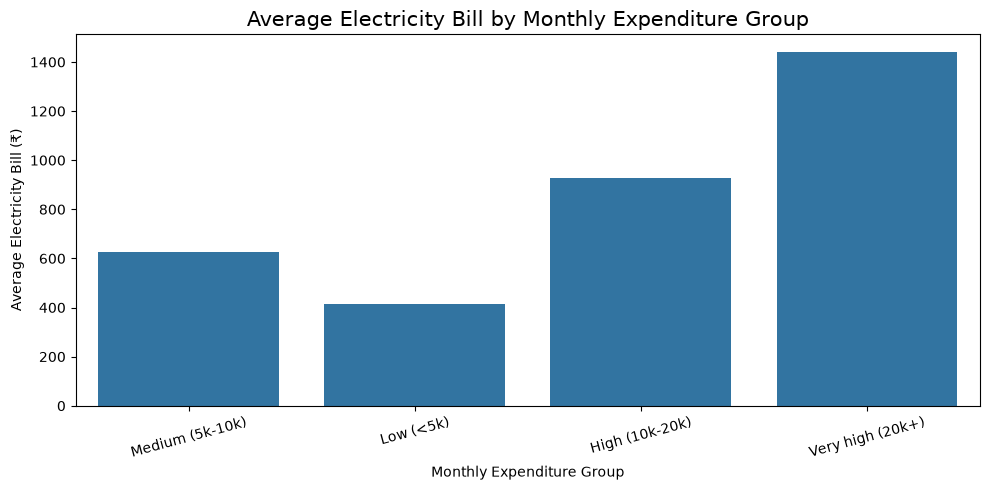

In [46]:
# Visualize expenditure vs electricity bill

# Visualize average electricity bill by expenditure group

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="expenditure_group",
    y="avg_monthly_elec_bill",
    estimator="mean",
    errorbar=None
)

plt.title("Average Electricity Bill by Monthly Expenditure Group", fontsize=15)
plt.xlabel("Monthly Expenditure Group")
plt.ylabel("Average Electricity Bill (₹)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### Monthly Expenditure vs Average Electricity Bill – Key Findings

1. Very high expenditure households have the highest average electricity bill at ₹1,440.67.
2. High expenditure households have an average bill of ₹928.78.
3. Medium expenditure households have an average bill of ₹626.54.
4. Low expenditure households have the lowest average bill at ₹413.77.
5. Average electricity bills increase consistently across the expenditure categories.
6. The results indicate a positive association between monthly expenditure and electricity bills.
7. This association does not establish a causal relationship.

In [47]:
# Household Size vs Monthly Expenditure

# to investigate whether larger households tend to have higher monthly expenditure.

# Calculate monthly expenditure by household size

household_expenditure_analysis = df.groupby(
    "household_size_group"
)["monthly_expenditure"].agg(
    ["count", "mean", "median"]
).round(2)

household_expenditure_analysis

,count,mean,median
household_size_group,,,
Large (7+),2578,8915.75,7000.0
Medium (4-6),9296,8064.84,7000.0
Small (1-3),2977,6799.91,6000.0


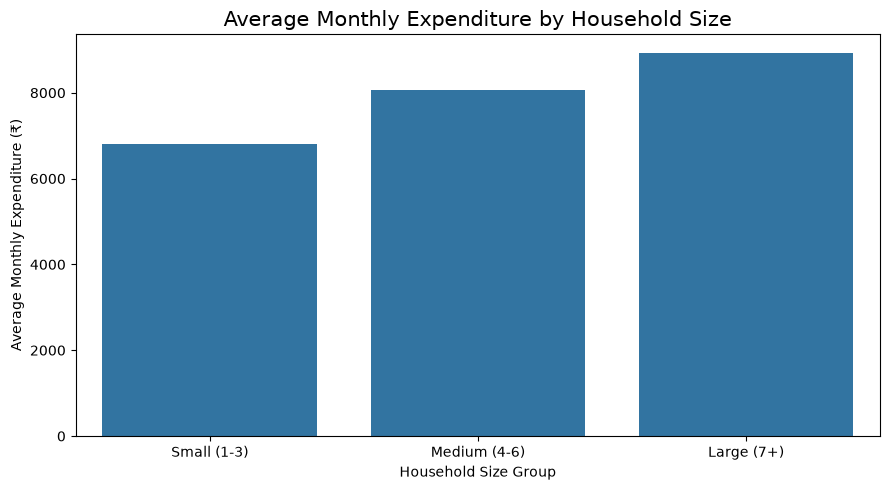

In [48]:
# Visualize household size vs monthly expenditure

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="household_size_group",
    y="monthly_expenditure",
    estimator="mean",
    errorbar=None
)

plt.title("Average Monthly Expenditure by Household Size", fontsize=15)
plt.xlabel("Household Size Group")
plt.ylabel("Average Monthly Expenditure (₹)")

plt.tight_layout()
plt.show()

### Household Size vs Monthly Expenditure – Key Findings

1. Large households (7+) have the highest average monthly expenditure at ₹8,915.75.
2. Medium households (4–6) have an average monthly expenditure of ₹8,064.84.
3. Small households (1–3) have the lowest average monthly expenditure at ₹6,799.91.
4. Median expenditure is ₹7,000 for both large and medium households.
5. Average monthly expenditure increases across the small, medium and large household categories.
6. The results indicate an association between household size and monthly expenditure.

In [49]:
# Age Group vs Average Electricity Bill

# to investigate whether average electricity bills differ across respondent age groups.

# Calculate average electricity bill by age group

age_bill_analysis = df.groupby(
    "age_group"
)["avg_monthly_elec_bill"].agg(
    ["count", "mean", "median"]
).round(2)

age_bill_analysis

,count,mean,median
age_group,,,
18-29,2969,677.15,500.00
30-44,6078,693.77,566.67
45-59,4237,713.84,566.67
60+,1567,745.45,650.00


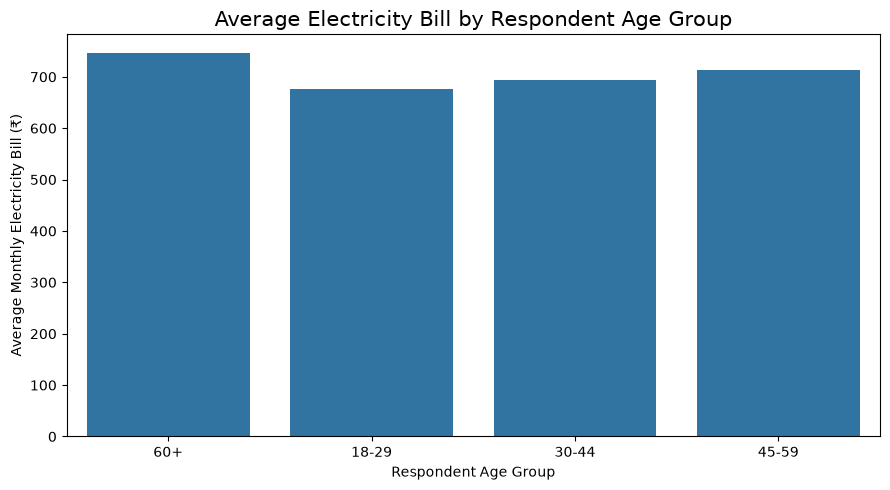

In [50]:
# Visualize age group vs electricity bill

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="age_group",
    y="avg_monthly_elec_bill",
    estimator="mean",
    errorbar=None
)

plt.title("Average Electricity Bill by Respondent Age Group", fontsize=15)
plt.xlabel("Respondent Age Group")
plt.ylabel("Average Monthly Electricity Bill (₹)")

plt.tight_layout()
plt.show()

### Age Group vs Average Electricity Bill – Key Findings

1. The 60+ age group has the highest average electricity bill at ₹745.45.
2. The 45–59 age group has an average bill of ₹713.84.
3. The 30–44 age group has an average bill of ₹693.77.
4. The 18–29 age group has the lowest average bill at ₹677.15.
5. Average electricity bills increase gradually across the respondent age categories.
6. The results indicate an association between respondent age group and household electricity bills, but do not establish causation.

In [51]:
# State vs Average Electricity Bill

state_bill_analysis = df.groupby(
    "state"
)["avg_monthly_elec_bill"].agg(
    ["count", "mean", "median"]
).round(2)

# Sort states by average electricity bill
state_bill_analysis = state_bill_analysis.sort_values(
    by="mean",
    ascending=False
)

state_bill_analysis

,count,mean,median
state,,,
Punjab,397,1628.47,1600.00
Haryana,383,1465.44,1500.00
Andhra Pradesh,498,1099.61,1055.00
Rajasthan,973,1068.84,900.00
Delhi,395,1056.63,833.33
Telangana,493,1003.86,933.33
Gujarat,798,980.84,833.33
Uttar Pradesh,1548,905.01,833.33
West Bengal,980,819.95,733.33


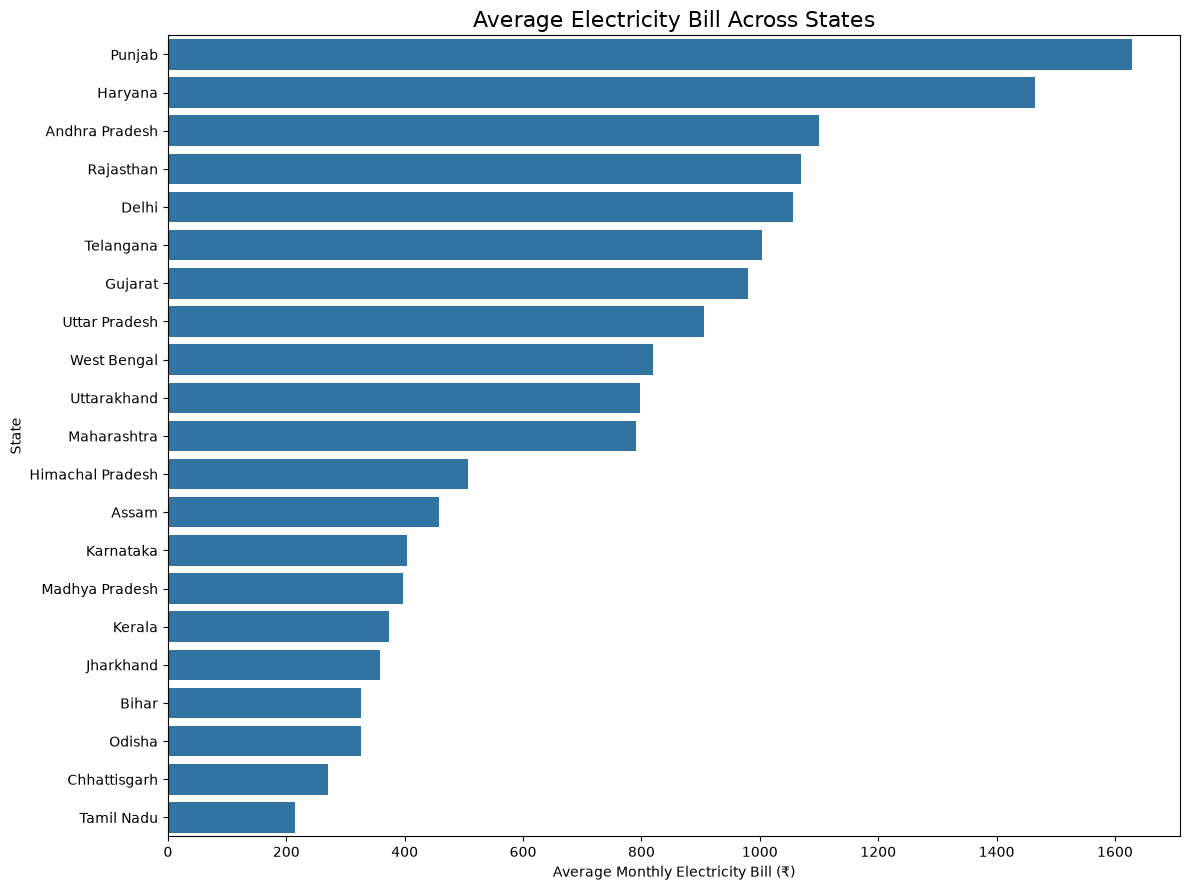

In [52]:
# Visualize average electricity bill by state

plt.figure(figsize=(12, 9))

sns.barplot(
    data=state_bill_analysis.reset_index(),
    x="mean",
    y="state"
)

plt.title("Average Electricity Bill Across States", fontsize=16)
plt.xlabel("Average Monthly Electricity Bill (₹)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

### State vs Average Electricity Bill – Key Findings

1. Punjab has the highest average electricity bill at ₹1,628.47.
2. Haryana ranks second with an average bill of ₹1,465.44.
3. Andhra Pradesh ranks third with an average bill of ₹1,099.61.
4. Tamil Nadu has the lowest average electricity bill at ₹215.48.
5. Kerala has an average electricity bill of ₹373.14 across 385 household records.
6. Considerable differences exist in average electricity bills across the 21 states.
7. These differences may be associated with household characteristics, electricity usage, tariffs and other factors.
8. Higher electricity bills should not automatically be interpreted as energy wastage.

In [53]:
# Household Size vs Electricity Bill Per Member

# examines electricity bill per household member.

# Calculate electricity bill per member by household size

bill_per_member_analysis = df.groupby(
    "household_size_group"
)["elec_bill_per_member"].agg(
    ["count", "mean", "median"]
).round(2)

bill_per_member_analysis

,count,mean,median
household_size_group,,,
Large (7+),2578,87.97,64.19
Medium (4-6),9296,148.80,116.67
Small (1-3),2977,292.93,220.00


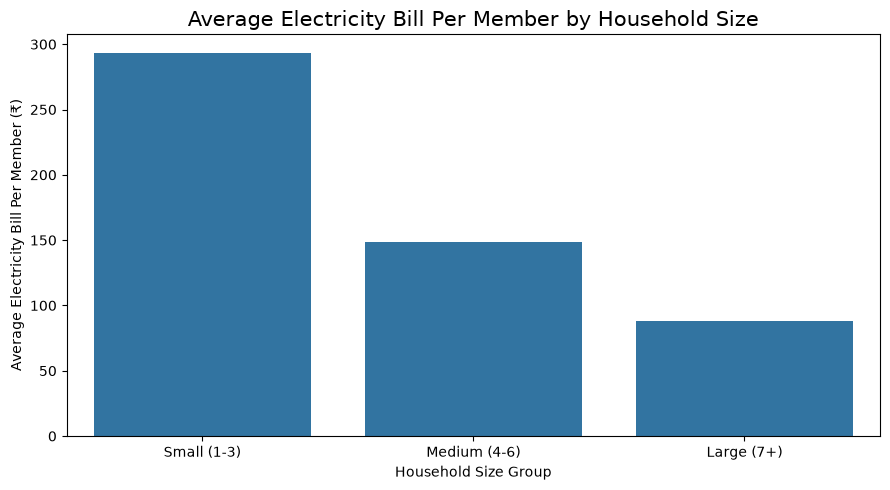

In [54]:
# Visualize the results

# Visualize electricity bill per member by household size

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="household_size_group",
    y="elec_bill_per_member",
    estimator="mean",
    errorbar=None
)

plt.title("Average Electricity Bill Per Member by Household Size", fontsize=15)
plt.xlabel("Household Size Group")
plt.ylabel("Average Electricity Bill Per Member (₹)")

plt.tight_layout()
plt.show()

### Household Size vs Electricity Bill Per Member – Key Findings

1. Small households (1–3) have the highest average electricity bill per member at ₹292.93.
2. Medium households (4–6) have an average bill per member of ₹148.80.
3. Large households (7+) have the lowest average bill per member at ₹87.97.
4. Average electricity bill per member decreases as household size increases.
5. Small households have considerably higher per-member bills than large households.
6. The results indicate an inverse association between household size and electricity bill per member.

In [55]:
# State vs Electricity Bill Per Member

state_bill_per_member = df.groupby(
    "state"
)["elec_bill_per_member"].agg(
    ["count", "mean", "median"]
).round(2)

# Sort by average bill per member
state_bill_per_member = state_bill_per_member.sort_values(
    by="mean",
    ascending=False
)

state_bill_per_member

,count,mean,median
state,,,
Haryana,383,462.57,375.00
Punjab,397,387.91,320.00
Andhra Pradesh,498,341.56,292.50
Telangana,493,300.92,250.00
Delhi,395,223.55,166.67
Gujarat,798,222.73,175.00
Rajasthan,973,219.99,180.00
West Bengal,980,212.95,177.78
Uttar Pradesh,1548,191.36,166.67


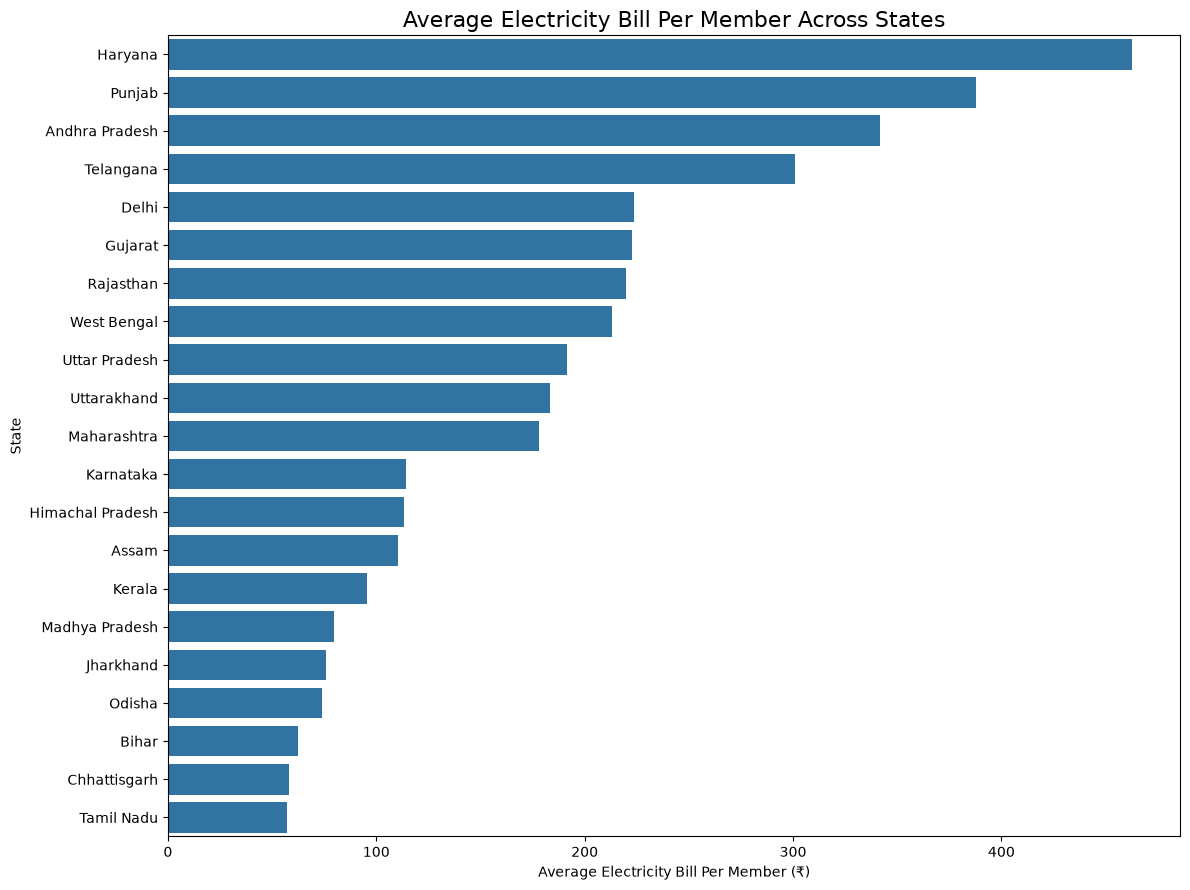

In [56]:
# Visualize average electricity bill per member by state

plt.figure(figsize=(12, 9))

sns.barplot(
    data=state_bill_per_member.reset_index(),
    x="mean",
    y="state"
)

plt.title("Average Electricity Bill Per Member Across States", fontsize=16)
plt.xlabel("Average Electricity Bill Per Member (₹)")
plt.ylabel("State")

plt.tight_layout()
plt.show()


### State vs Electricity Bill Per Member – Key Findings

1. Haryana has the highest average electricity bill per member at ₹462.57.
2. Punjab ranks second with ₹387.91 per member.
3. Andhra Pradesh ranks third with ₹341.56 per member.
4. Tamil Nadu has the lowest average electricity bill per member at ₹57.38.
5. Kerala has an average electricity bill per member of ₹95.67.
6. Considerable differences exist in per-member electricity bills across the 21 states.
7. These differences may be associated with household characteristics, electricity usage, tariffs and other factors.
8. Higher per-member electricity bills should not automatically be interpreted as energy wastage.

In [57]:
# Monthly Expenditure vs Electricity Bill Share (%).

# We already have an engineered feature called bill_share_of_expenditure_pct.

# For example, 
# if a household spends ₹1,000 on electricity out of a total monthly expenditure of ₹10,000,
# its electricity bill share is 10%

# Calculate electricity bill share by expenditure group

bill_share_analysis = df.groupby(
    "expenditure_group"
)["bill_share_of_expenditure_pct"].agg(
    ["count", "mean", "median"]
).round(2)

bill_share_analysis

,count,mean,median
expenditure_group,,,
High (10k-20k),3830,7.90,6.67
Low (<5k),2618,13.67,9.67
Medium (5k-10k),7771,9.98,8.25
Very high (20k+),632,6.30,5.12


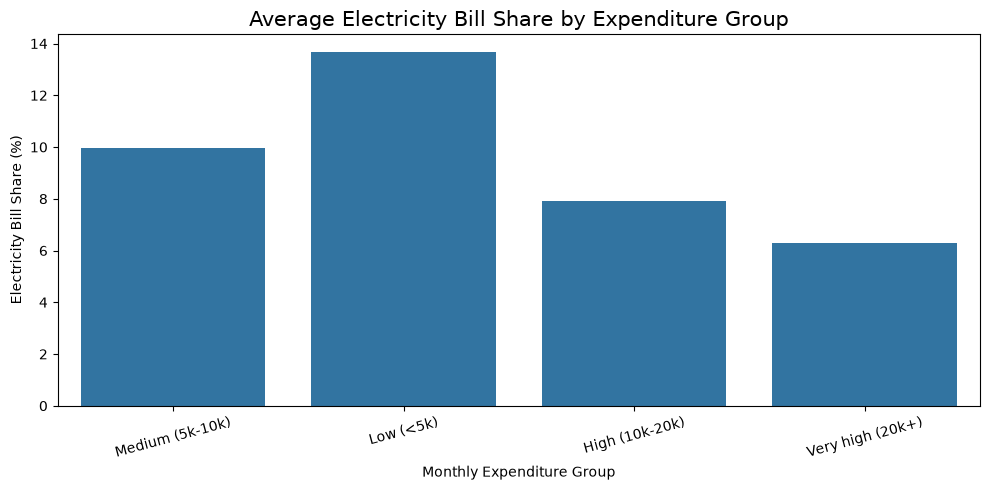

In [58]:
# isualize the results

# Visualize electricity bill share by expenditure group

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="expenditure_group",
    y="bill_share_of_expenditure_pct",
    estimator="mean",
    errorbar=None
)

plt.title("Average Electricity Bill Share by Expenditure Group", fontsize=15)
plt.xlabel("Monthly Expenditure Group")
plt.ylabel("Electricity Bill Share (%)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### Monthly Expenditure vs Electricity Bill Share – Key Findings

1. Low-expenditure households have the highest average electricity bill share at 13.67%.
2. Medium-expenditure households have an average bill share of 9.98%.
3. High-expenditure households have an average bill share of 7.90%.
4. Very high-expenditure households have the lowest average bill share at 6.30%.
5. Electricity bill share decreases across the monthly expenditure categories.
6. Lower-expenditure households allocate a larger proportion of their expenditure to electricity.
7. This relationship should be interpreted carefully because monthly expenditure is used to calculate the electricity bill share and define the expenditure categories.

In [59]:
# Age Group vs Monthly Expenditure

# Calculate monthly expenditure by age group

age_expenditure_analysis = df.groupby(
    "age_group"
)["monthly_expenditure"].agg(
    ["count", "mean", "median"]
).round(2)

age_expenditure_analysis

,count,mean,median
age_group,,,
18-29,2969,7988.28,7000.0
30-44,6078,7888.68,6500.0
45-59,4237,8081.70,7000.0
60+,1567,7844.36,6000.0


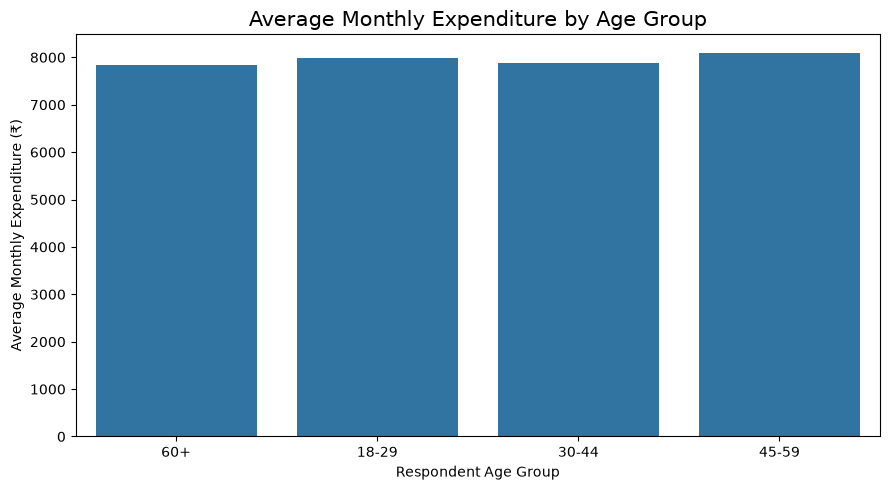

In [60]:
# Visualize average monthly expenditure by age group

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="age_group",
    y="monthly_expenditure",
    estimator="mean",
    errorbar=None
)

plt.title("Average Monthly Expenditure by Age Group", fontsize=15)
plt.xlabel("Respondent Age Group")
plt.ylabel("Average Monthly Expenditure (₹)")

plt.tight_layout()
plt.show()

### Age Group vs Monthly Expenditure – Key Findings

1. The 45–59 age group has the highest average monthly expenditure at ₹8,081.70.
2. The 18–29 age group has an average monthly expenditure of ₹7,988.28.
3. The 30–44 age group has an average monthly expenditure of ₹7,888.68.
4. The 60+ age group has the lowest average monthly expenditure at ₹7,844.36.
5. Average monthly expenditure varies only slightly across the four age groups.
6. Respondent age group does not show a strong difference in average household expenditure in this comparison.

In [61]:
# State vs Monthly Expenditure

# Calculate monthly expenditure by state

state_expenditure_analysis = df.groupby(
    "state"
)["monthly_expenditure"].agg(
    ["count", "mean", "median"]
).round(2)

# Sort states by average monthly expenditure
state_expenditure_analysis = state_expenditure_analysis.sort_values(
    by="mean",
    ascending=False
)

state_expenditure_analysis

,count,mean,median
state,,,
Delhi,395,14306.48,13000.0
Rajasthan,973,10701.76,10000.0
Uttarakhand,384,10419.72,10000.0
Himachal Pradesh,384,10371.09,10000.0
Maharashtra,1409,10093.62,8000.0
Haryana,383,9482.79,10000.0
Punjab,397,8433.25,8000.0
Kerala,385,8379.52,8000.0
Gujarat,798,8279.65,7000.0


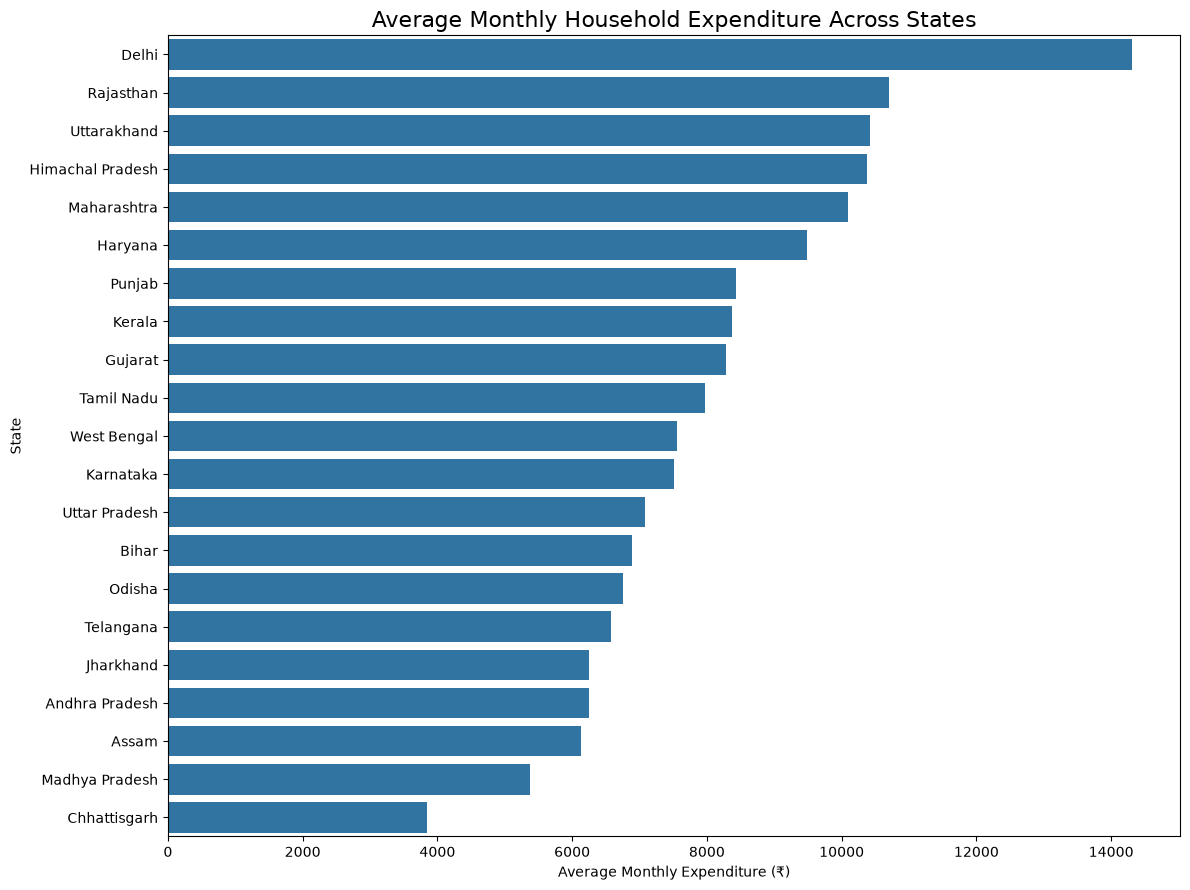

In [62]:
# Visualize average monthly expenditure by state

plt.figure(figsize=(12, 9))

sns.barplot(
    data=state_expenditure_analysis.reset_index(),
    x="mean",
    y="state"
)

plt.title("Average Monthly Household Expenditure Across States", fontsize=16)
plt.xlabel("Average Monthly Expenditure (₹)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

### State vs Monthly Expenditure – Key Findings

1. Delhi has the highest average monthly household expenditure at ₹14,306.48.
2. Rajasthan ranks second with ₹10,701.76.
3. Uttarakhand has an average expenditure of ₹10,419.72.
4. Chhattisgarh has the lowest average monthly expenditure at ₹3,842.68.
5. Kerala has an average monthly expenditure of ₹8,379.52 across 385 households.
6. Considerable differences exist in average monthly expenditure across the 21 states.
7. These differences may be associated with household characteristics, cost of living and other factors.

In [63]:
# Household Size vs Expenditure Per Member

# Calculate expenditure per member by household size

expenditure_per_member_analysis = df.groupby(
    "household_size_group"
)["expenditure_per_member"].agg(
    ["count", "mean", "median"]
).round(2)

expenditure_per_member_analysis

,count,mean,median
household_size_group,,,
Large (7+),2578,1059.19,857.14
Medium (4-6),9296,1706.74,1500.00
Small (1-3),2977,2816.78,2500.00


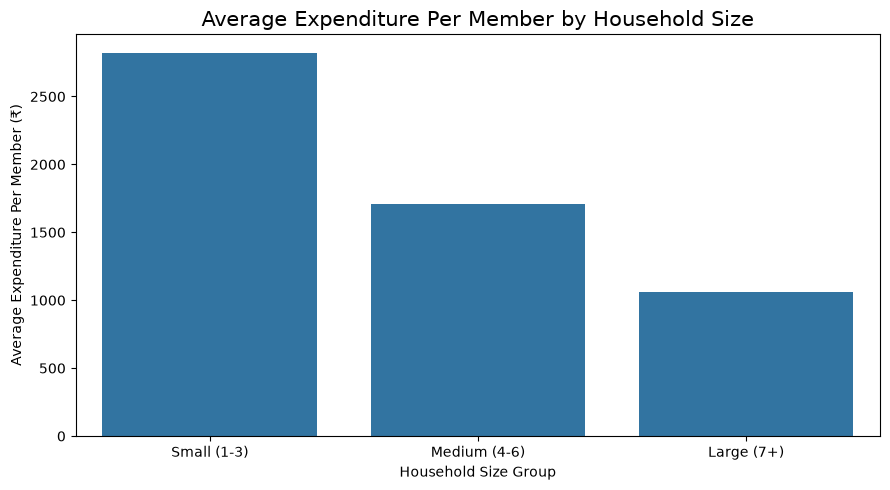

In [64]:
# Visualize the results

# Visualize average expenditure per member by household size

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="household_size_group",
    y="expenditure_per_member",
    estimator="mean",
    errorbar=None
)

plt.title("Average Expenditure Per Member by Household Size", fontsize=15)
plt.xlabel("Household Size Group")
plt.ylabel("Average Expenditure Per Member (₹)")

plt.tight_layout()
plt.show()

### Household Size vs Expenditure Per Member – Key Findings

1. Small households (1–3) have the highest average expenditure per member at ₹2,816.78.
2. Medium households (4–6) have an average expenditure per member of ₹1,706.74.
3. Large households (7+) have the lowest average expenditure per member at ₹1,059.19.
4. Average expenditure per member decreases as household size increases.
5. Small households have approximately 2.66 times the average per-member expenditure of large households.
6. The results indicate an inverse association between household size and expenditure per member.

In [65]:
# State vs Expenditure Per Member

# Calculate expenditure per member by state

state_expenditure_per_member = df.groupby(
    "state"
)["expenditure_per_member"].agg(
    ["count", "mean", "median"]
).round(2)

# Sort by average expenditure per member
state_expenditure_per_member = state_expenditure_per_member.sort_values(
    by="mean",
    ascending=False
)

state_expenditure_per_member

,count,mean,median
state,,,
Delhi,395,2980.43,2600.00
Haryana,383,2615.73,2000.00
Uttarakhand,384,2336.60,2000.00
Himachal Pradesh,384,2324.54,2000.00
Maharashtra,1409,2256.53,1750.00
Kerala,385,2193.88,2000.00
Rajasthan,973,2128.43,2000.00
Tamil Nadu,969,2107.48,1750.00
Karnataka,788,2003.77,1500.00


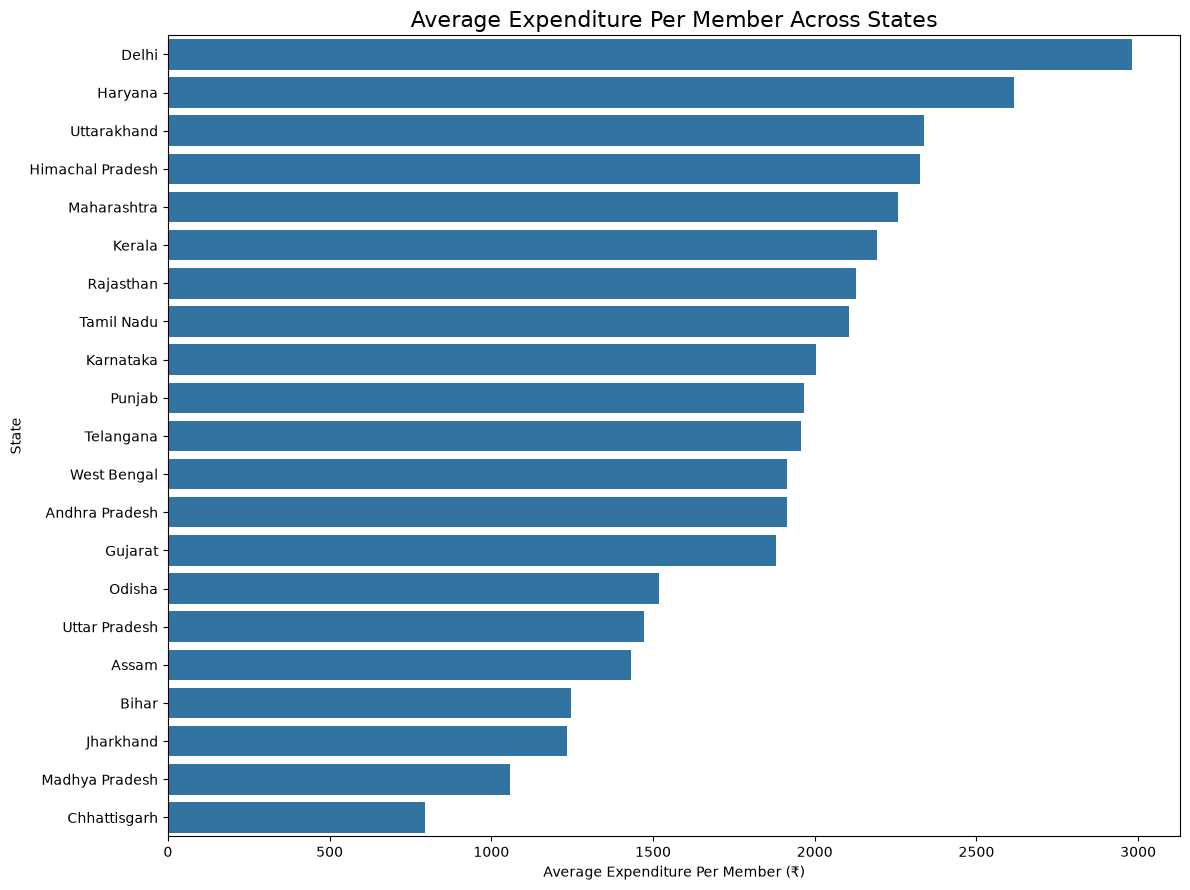

In [66]:
# Visualize average expenditure per member by state

plt.figure(figsize=(12, 9))

sns.barplot(
    data=state_expenditure_per_member.reset_index(),
    x="mean",
    y="state"
)

plt.title("Average Expenditure Per Member Across States", fontsize=16)
plt.xlabel("Average Expenditure Per Member (₹)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

### State vs Expenditure Per Member – Key Findings

1. Delhi has the highest average expenditure per member at ₹2,980.43.
2. Haryana ranks second with ₹2,615.73.
3. Uttarakhand has an average expenditure per member of ₹2,336.60.
4. Chhattisgarh has the lowest average at ₹795.79.
5. Kerala has an average expenditure per member of ₹2,193.88.
6. Considerable differences exist in average expenditure per member across the 21 states.
7. These differences may be associated with household characteristics, cost of living and other factors.

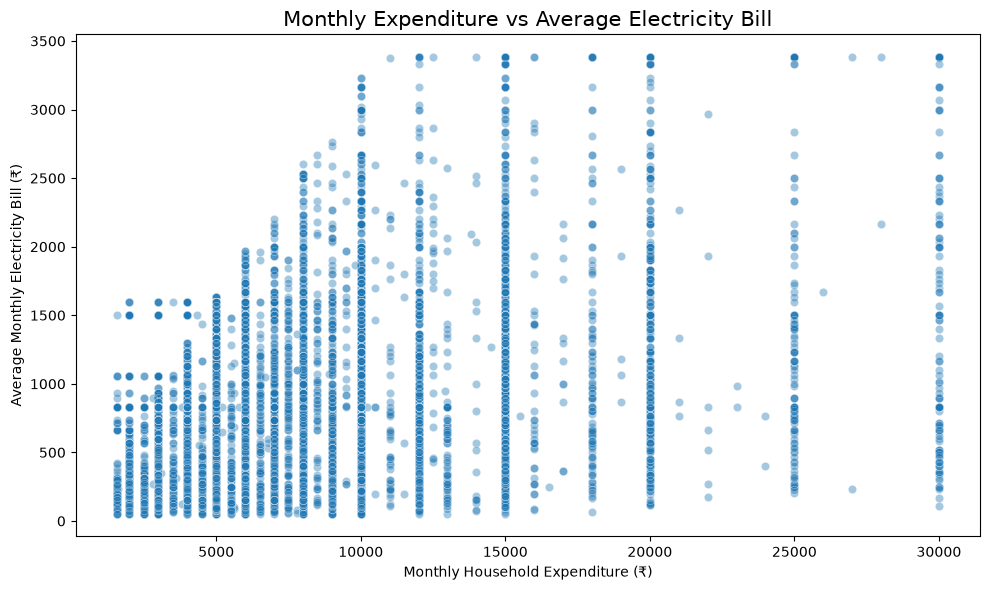

In [67]:
# Electricity Bill vs Monthly Expenditure

# examine whether 
# households with higher monthly expenditure also tend to have higher electricity bills.

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="monthly_expenditure",
    y="avg_monthly_elec_bill",
    alpha=0.4
)

plt.title("Monthly Expenditure vs Average Electricity Bill", fontsize=15)
plt.xlabel("Monthly Household Expenditure (₹)")
plt.ylabel("Average Monthly Electricity Bill (₹)")

plt.tight_layout()
plt.show()

# Interpretation

we can observe:
1. Possible positive relationship: Electricity bills generally tend to be higher among households with greater monthly expenditure.
2. Wide variation: Households with similar expenditure levels can have very different electricity bills.
3. High-expenditure households: Even among households spending ₹15,000–₹30,000 per month, electricity bills vary considerably.
4. Vertical clusters: The repeated vertical patterns suggest that monthly expenditure values are recorded at particular levels rather than being continuously distributed.

### Key Findings

- The scatter plot suggests a possible positive relationship between monthly household expenditure and average electricity bills.
- Electricity bills vary considerably among households with similar expenditure levels.
- Higher household expenditure does not always correspond to a higher electricity bill.
- The vertical clusters indicate that monthly expenditure values occur at specific recorded levels.
- The relationship represents an association and does not establish causation or prove energy wastage.

In [68]:
# Correlation Analysis

correlation = df["monthly_expenditure"].corr(
    df["avg_monthly_elec_bill"]
)

print("Pearson Correlation:", correlation)

Pearson Correlation: 0.42189322566860193


### Key Findings

- Pearson correlation between monthly expenditure and average electricity bill is approximately 0.4219.
- This indicates a moderate positive linear relationship.
- Households with higher monthly expenditure tend to have higher electricity bills.
- The relationship is not very strong, suggesting that other household factors may also influence electricity bills.
- Correlation does not imply causation.

In [69]:
# Correlation with Other Household Features
# calculate how different numerical household features are correlated with avg_monthly_elec_bill.
# Select relevant numerical features

correlation_features = [
    "avg_monthly_elec_bill",
    "monthly_expenditure",
    "elec_bill_per_member",
    "expenditure_per_member",
    "bill_share_of_expenditure_pct",
    "respondent_age"
]

correlation_matrix = df[correlation_features].corr()

correlation_matrix["avg_monthly_elec_bill"].sort_values(
    ascending=False
)


avg_monthly_elec_bill            1.000000
elec_bill_per_member             0.754597
bill_share_of_expenditure_pct    0.617687
monthly_expenditure              0.421893
expenditure_per_member           0.316815
respondent_age                   0.040797
Name: avg_monthly_elec_bill, dtype: float64

### Key Findings

- Electricity bill per member has a strong positive correlation (0.7546) with average monthly electricity bills.
- Bill share of expenditure shows a moderate positive correlation (0.6177).
- Monthly expenditure has a moderate positive correlation (0.4219).
- Expenditure per member has a weak positive correlation (0.3168).
- Respondent age has almost no linear correlation (0.0408).
- Derived features containing the electricity bill should be excluded from ML input features to prevent target leakage.

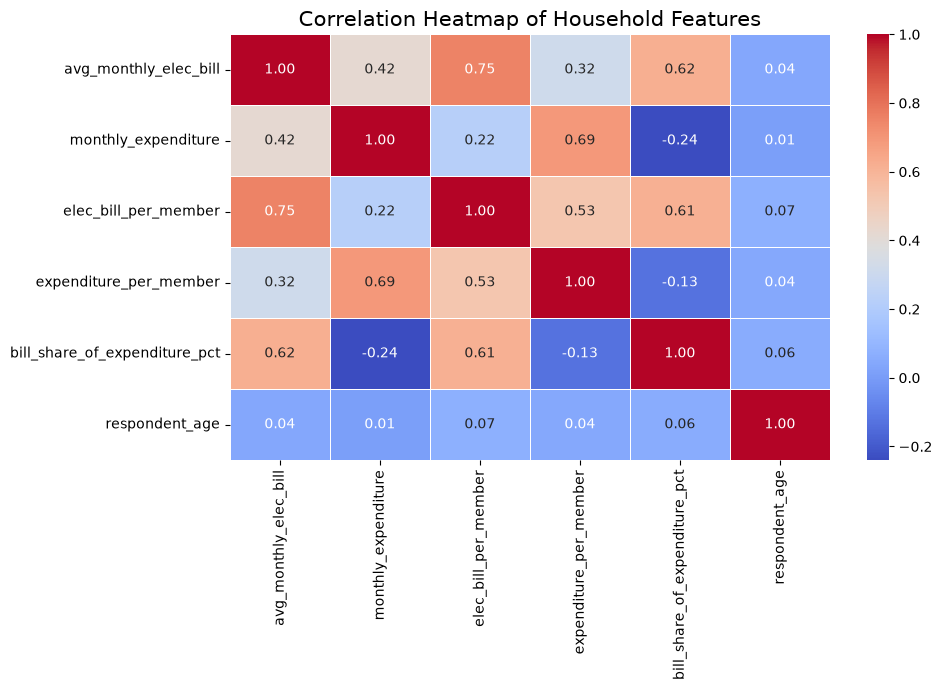

In [70]:
# Correlation Heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Household Features", fontsize=15)
plt.tight_layout()
plt.show()

### Key Findings

- Electricity bill per member has a strong positive correlation (0.75) with the average monthly electricity bill.
- Monthly expenditure and expenditure per member have a strong positive correlation (0.69).
- Bill share of expenditure has a moderate positive correlation (0.62) with the electricity bill.
- Monthly expenditure and bill share of expenditure show a weak negative correlation (-0.24).
- Respondent age has very weak correlations with the selected household features.
- Some strong correlations are expected because certain features are mathematically derived from other variables.
- Correlation does not imply causation.

# 5. Overall Key Findings – Bivariate Analysis

1. Household size: Larger households have higher average electricity bills, but smaller households have higher electricity bills per member.

2. Monthly expenditure: Households with higher monthly expenditure generally have higher electricity bills.

3. Age group: Average electricity bills show some variation across age groups, with the 60+ group having the highest mean.

4. State-wise comparison: Electricity bills and expenditure per member vary considerably across states.

5. Electricity bill relationship: Monthly expenditure has a moderate positive correlation (0.4219) with average monthly electricity bills.

6. Correlation analysis: Electricity bill per member has a strong positive correlation (0.7546) with the average monthly electricity bill. This is partly due to mathematical dependency.

7. Respondent age: Respondent age has almost no linear correlation (0.0408) with average monthly electricity bills.

Overall, household size, expenditure and geographical location show useful patterns in electricity bill differences. These relationships are exploratory and do not independently establish energy wastage or causation.

# Section 6 – Household Features Analysis

In [71]:
# Household Size vs People Per Bedroom

# examine whether household size is associated with the number of people per bedroom.

# First, calculate the average and median people per bedroom for each household-size group.

household_features = df.groupby("household_size_group")[
    "people_per_bedroom"
].agg(
    ["count", "mean", "median"]
)

household_features

,count,mean,median
household_size_group,,,
Large (7+),2578,4.278995,3.5
Medium (4-6),9296,3.090585,2.5
Small (1-3),2977,1.902482,2.0


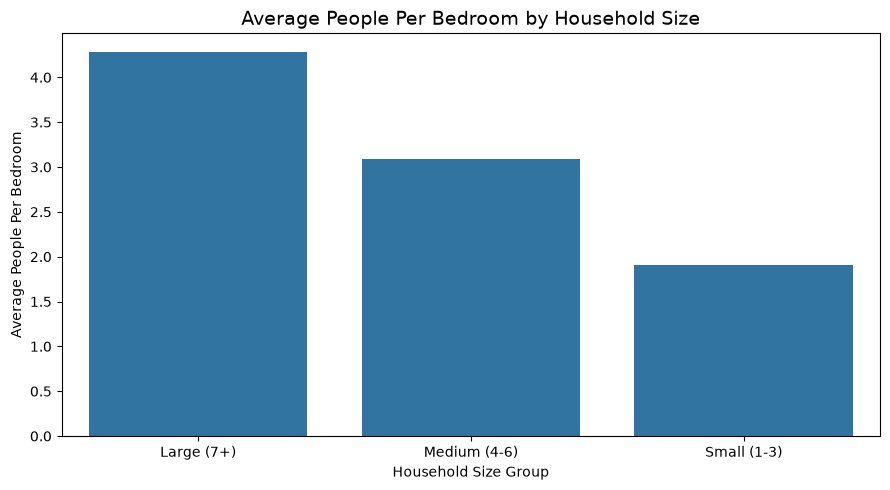

In [72]:
# Visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=household_features.reset_index(),
    x="household_size_group",
    y="mean"
)

plt.title("Average People Per Bedroom by Household Size", fontsize=14)
plt.xlabel("Household Size Group")
plt.ylabel("Average People Per Bedroom")

plt.tight_layout()
plt.show()

### Key Findings

- Large households have the highest average number of people per bedroom (4.28).
- Medium households have an average of 3.09 people per bedroom.
- Small households have the lowest average of 1.90 people per bedroom.
- The average number of people per bedroom increases with household size.
- This suggests that larger households generally have more people sharing each bedroom.

In [73]:
# Household Size vs Number of Bedrooms.

bedroom_analysis = df.groupby("household_size_group")[
    "bedrooms"
].agg(
    ["count", "mean", "median"]
)

bedroom_analysis

,count,mean,median
household_size_group,,,
Large (7+),2578,2.562839,2.0
Medium (4-6),9296,1.933950,2.0
Small (1-3),2977,1.572052,1.0


### Key Findings

- Large households have the highest average number of bedrooms (2.56).
- Medium households have an average of 1.93 bedrooms.
- Small households have the lowest average of 1.57 bedrooms.
- Larger households generally have more bedrooms than smaller households.
- However, larger households also tend to have more people sharing each bedroom.

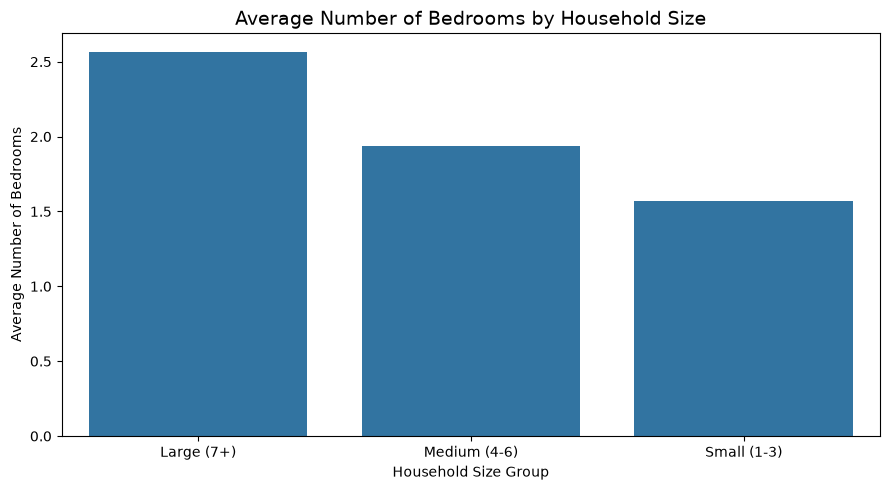

In [74]:
# Visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=bedroom_analysis.reset_index(),
    x="household_size_group",
    y="mean"
)

plt.title("Average Number of Bedrooms by Household Size", fontsize=14)
plt.xlabel("Household Size Group")
plt.ylabel("Average Number of Bedrooms")

plt.tight_layout()
plt.show()

### Key Findings

- Large households have the highest average number of bedrooms (2.56).
- Medium households have an average of 1.93 bedrooms.
- Small households have the lowest average of 1.57 bedrooms.
- The average number of bedrooms increases with household size.
- Despite having more bedrooms, larger households also tend to have more people sharing each bedroom.

In [75]:
# Household Size vs Land Area

land_area_analysis = df.groupby("household_size_group")[
    "land_area_sqft"
].agg(
    ["count", "mean", "median"]
)

land_area_analysis

,count,mean,median
household_size_group,,,
Large (7+),2578,1448.918988,1000.0
Medium (4-6),9296,1335.208268,900.0
Small (1-3),2977,1205.250388,800.0


### Key Findings

- Large households have the highest average land area (1,448.92 sq. ft.).
- Medium households have an average land area of 1,335.21 sq. ft.
- Small households have the lowest average land area (1,205.25 sq. ft.).
- Median land area also increases across household-size groups.
- Larger households tend to occupy properties with slightly greater land areas, although household size alone does not determine property size.

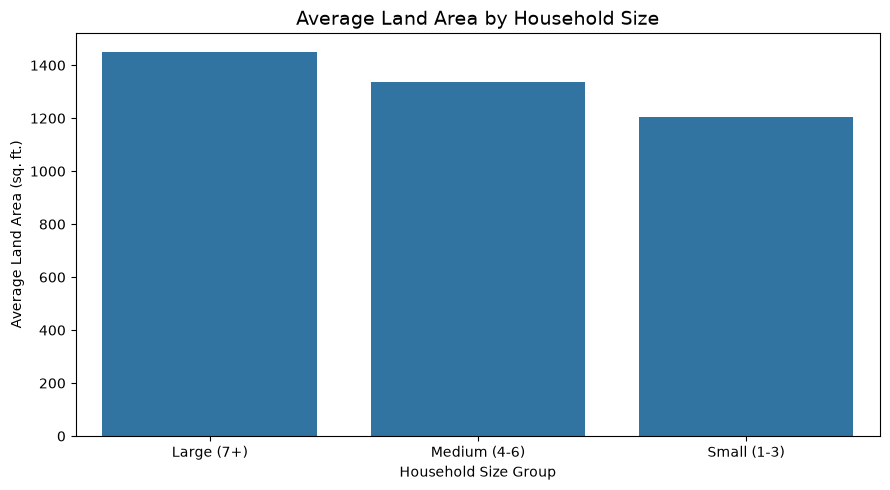

In [76]:
# Visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=land_area_analysis.reset_index(),
    x="household_size_group",
    y="mean"
)

plt.title("Average Land Area by Household Size", fontsize=14)
plt.xlabel("Household Size Group")
plt.ylabel("Average Land Area (sq. ft.)")

plt.tight_layout()
plt.show()

### Key Findings

- Large households have the highest average land area (1,448.92 sq. ft.).
- Medium households have an average land area of 1,335.21 sq. ft.
- Small households have the lowest average land area (1,205.25 sq. ft.).
- Median land area also increases across household-size groups.
- Larger households tend to occupy properties with slightly greater land areas, although household size alone does not determine property size

In [77]:
# Household Size vs Electricity Access

[col for col in df.columns if "elec" in col.lower()]

['q312_grid_elec_meter_yn',
 'avg_monthly_elec_bill',
 'q324_prim_source_electricity',
 'q326_satis_electricity',
 'q451_elec_coil_stove_use_7',
 'q471_elec_water_purifier_1_yn',
 'q471_elec_kettle_3_yn',
 'q471_elec_atta_chakki_4_yn',
 'q514_1_lpg_electric_cook_4',
 'q526_e_elec_rice_cooker_yn',
 'q528_elec_cook_allneeds',
 'q528_elec_cook_fast',
 'q528_elec_cook_cheap',
 'q608_a_ifprep_control_elec_exp',
 'q608_b_ifprep_elec_bill_change',
 'q608_d_ifprep_elec_theft',
 'q610_elec_bill_physical_yn',
 'avg_monthly_elec_bill_was_missing',
 'elec_bill_per_member']

In [78]:
# Check electricity access responses

df["q312_grid_elec_meter_yn"].value_counts(dropna=False)

q312_grid_elec_meter_yn
1.0    13065
0.0      976
NaN      510
2.0      300
Name: count, dtype: int64

In [79]:
# Check responses across household sizes

electricity_access = pd.crosstab(
    df["household_size_group"],
    df["q312_grid_elec_meter_yn"],
    margins=True
)

electricity_access



q312_grid_elec_meter_yn,0.0,1.0,2.0,All
household_size_group,,,,
Large (7+),238,2161,90,2489
Medium (4-6),549,8288,181,9018
Small (1-3),189,2616,29,2834
All,976,13065,300,14341


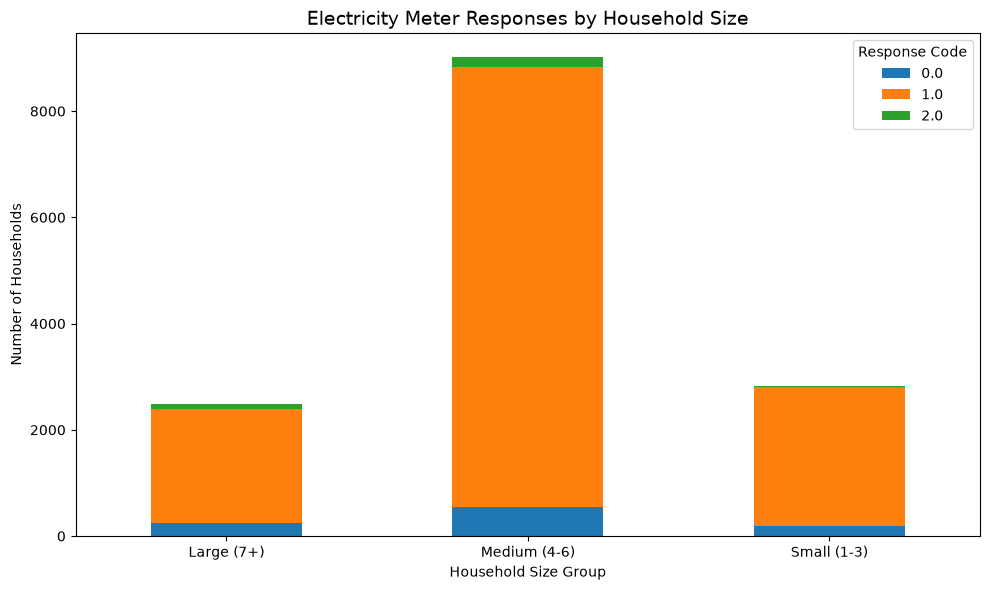

In [80]:
# Visualize the response distribution

electricity_access_plot = pd.crosstab(
    df["household_size_group"],
    df["q312_grid_elec_meter_yn"]
)

electricity_access_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Electricity Meter Responses by Household Size", fontsize=14)
plt.xlabel("Household Size Group")
plt.ylabel("Number of Households")
plt.xticks(rotation=0)
plt.legend(title="Response Code")

plt.tight_layout()
plt.show()

### Key Findings

- Response code 1.0 is the most frequently recorded response across all household-size groups.
- Medium households account for the highest number of code 1.0 responses (8,288).
- Large households have 2,161 code 1.0 responses, while small households have 2,616.
- Response code 0.0 and 2.0 occur less frequently.
- There are 510 missing responses in the original column.
- The meanings of response codes must be verified using the CEEW questionnaire or codebook before interpreting them as electricity access categories.

In [81]:
# Household Size vs Electricity Bill Share

bill_share_analysis = df.groupby("household_size_group")[
    "bill_share_of_expenditure_pct"
].agg(
    ["count", "mean", "median"]
)

bill_share_analysis

,count,mean,median
household_size_group,,,
Large (7+),2578,9.189368,6.94
Medium (4-6),9296,9.603305,7.75
Small (1-3),2977,11.632849,8.75


### Key Findings

- Small households have the highest average electricity bill share (11.63%).
- Medium households have an average bill share of 9.60%.
- Large households have the lowest average bill share (9.19%).
- Smaller households tend to allocate a higher proportion of their monthly expenditure to electricity bills.
- These are descriptive relationships and do not establish energy wastage.

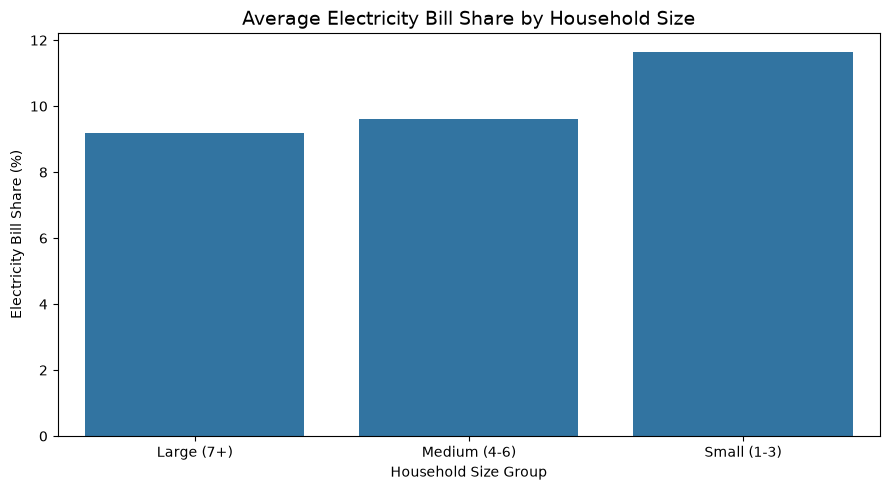

In [82]:
# Visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=bill_share_analysis.reset_index(),
    x="household_size_group",
    y="mean"
)

plt.title("Average Electricity Bill Share by Household Size", fontsize=14)
plt.xlabel("Household Size Group")
plt.ylabel("Electricity Bill Share (%)")

plt.tight_layout()
plt.show()

### Key Findings

- Small households have the highest average electricity bill share (11.63%).
- Medium households have an average bill share of 9.60%.
- Large households have the lowest average bill share (9.19%).
- Smaller households tend to allocate a higher proportion of their monthly expenditure to electricity bills.
- These are descriptive relationships and do not establish energy wastage.

In [83]:
# Household Size vs Electricity Bill Per Member

bill_per_member_analysis = df.groupby("household_size_group")[
    "elec_bill_per_member"
].agg(
    ["count", "mean", "median"]
)

bill_per_member_analysis

,count,mean,median
household_size_group,,,
Large (7+),2578,87.970427,64.195
Medium (4-6),9296,148.801045,116.670
Small (1-3),2977,292.925794,220.000


### Key Findings

- Small households have the highest average electricity bill per member (₹292.93).
- Medium households have an average of ₹148.80 per member.
- Large households have the lowest average of ₹87.97 per member.
- Electricity bill per member decreases as household size increases.
- This may indicate the effect of sharing household electricity expenses among more members.
- Higher per-member electricity costs do not automatically indicate energy wastage.

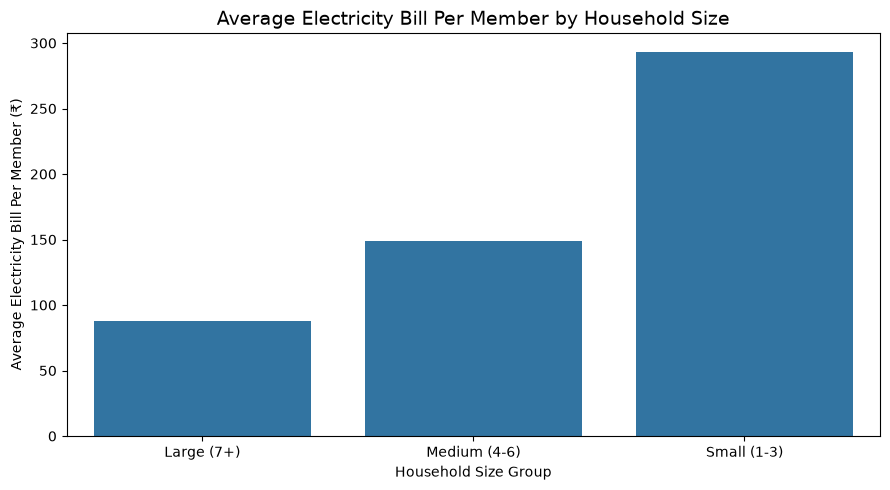

In [84]:
# visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=bill_per_member_analysis.reset_index(),
    x="household_size_group",
    y="mean"
)

plt.title("Average Electricity Bill Per Member by Household Size", fontsize=14)
plt.xlabel("Household Size Group")
plt.ylabel("Average Electricity Bill Per Member (₹)")

plt.tight_layout()
plt.show()

In [85]:
# Household Size vs Monthly Expenditure Per Member

expenditure_per_member_analysis = df.groupby("household_size_group")[
    "expenditure_per_member"
].agg(
    ["count", "mean", "median"]
)

expenditure_per_member_analysis

,count,mean,median
household_size_group,,,
Large (7+),2578,1059.192168,857.14
Medium (4-6),9296,1706.742214,1500.00
Small (1-3),2977,2816.777978,2500.00


### Key Findings

- Small households have the highest average expenditure per member (₹2,816.78).
- Medium households have an average expenditure per member of ₹1,706.74.
- Large households have the lowest average expenditure per member (₹1,059.19).
- Average expenditure per member decreases as household size increases.
- This may indicate the effect of sharing household expenses among more members.

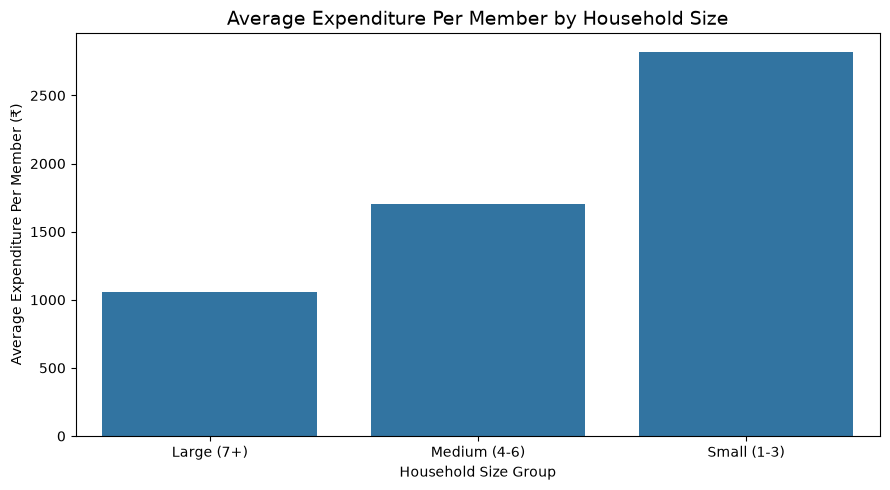

In [86]:
# visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=expenditure_per_member_analysis.reset_index(),
    x="household_size_group",
    y="mean"
)

plt.title("Average Expenditure Per Member by Household Size", fontsize=14)
plt.xlabel("Household Size Group")
plt.ylabel("Average Expenditure Per Member (₹)")

plt.tight_layout()
plt.show()

### Key Findings

- Small households have the highest average expenditure per member (₹2,816.78).
- Medium households have an average expenditure per member of ₹1,706.74.
- Large households have the lowest average expenditure per member (₹1,059.19).
- Average expenditure per member decreases as household size increases.
- This may indicate the effect of sharing household expenses among more members.

In [87]:
# Household Age Group vs Household Size

age_household_analysis = pd.crosstab(
    df["age_group"],
    df["household_size_group"]
)

age_household_analysis

household_size_group,Large (7+),Medium (4-6),Small (1-3)
age_group,,,
18-29,489,1885,595
30-44,878,4243,957
45-59,803,2523,911
60+,408,645,514


### Key Findings

- Medium-sized households are the most common category across all respondent age groups.
- The 30–44 age group has the highest number of medium-sized households (4,243).
- The 45–59 age group has 2,523 medium-sized households.
- Respondents aged 60+ have 514 small households.
- Household-size distributions vary across respondent age groups.

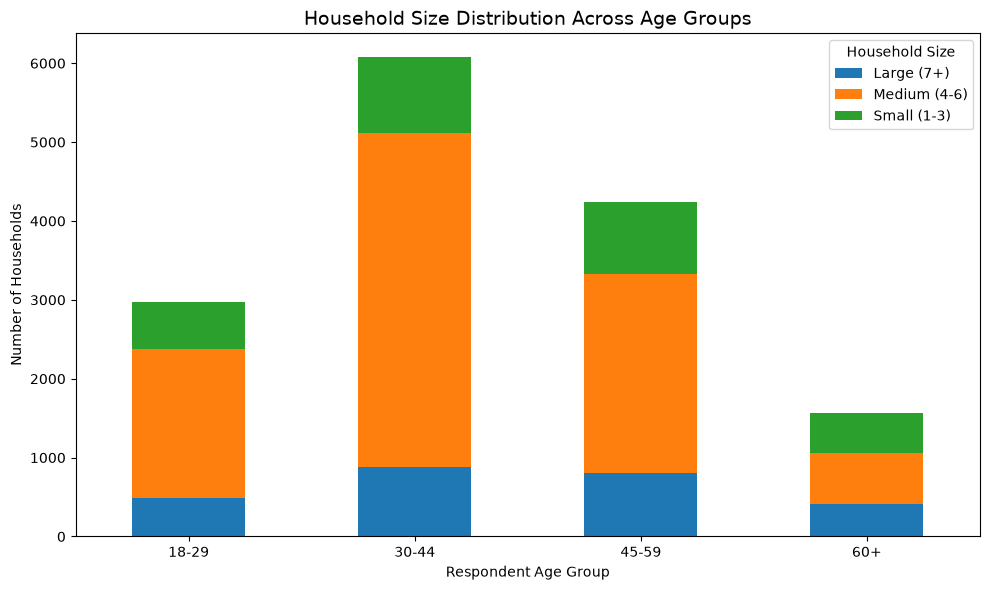

In [88]:
# visualization
age_household_analysis.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Household Size Distribution Across Age Groups", fontsize=14)
plt.xlabel("Respondent Age Group")
plt.ylabel("Number of Households")
plt.xticks(rotation=0)
plt.legend(title="Household Size")

plt.tight_layout()
plt.show()

### Key Findings

- Medium-sized households are the most common category across all respondent age groups.
- The 30–44 age group has the highest number of medium-sized households (4,243).
- The 45–59 age group has 2,523 medium-sized households.
- Respondents aged 60+ have 514 small households.
- Household-size distributions vary across respondent age groups.

In [89]:
# Age Group vs People Per Bedroom

age_bedroom_analysis = df.groupby("age_group")[
    "people_per_bedroom"
].agg(
    ["count", "mean", "median"]
)

age_bedroom_analysis

,count,mean,median
age_group,,,
18-29,2969,3.136096,3.0
30-44,6078,3.172474,3.0
45-59,4237,2.990491,2.5
60+,1567,2.655354,2.0


### Key Findings

- Respondents aged 30–44 have the highest average people per bedroom (3.17).
- Respondents aged 18–29 have an average of 3.14 people per bedroom.
- The 45–59 age group has an average of 2.99.
- The 60+ age group has the lowest average of 2.66.
- The average number of people per bedroom generally decreases across the older respondent age groups.
- These findings describe associations and do not establish causation.

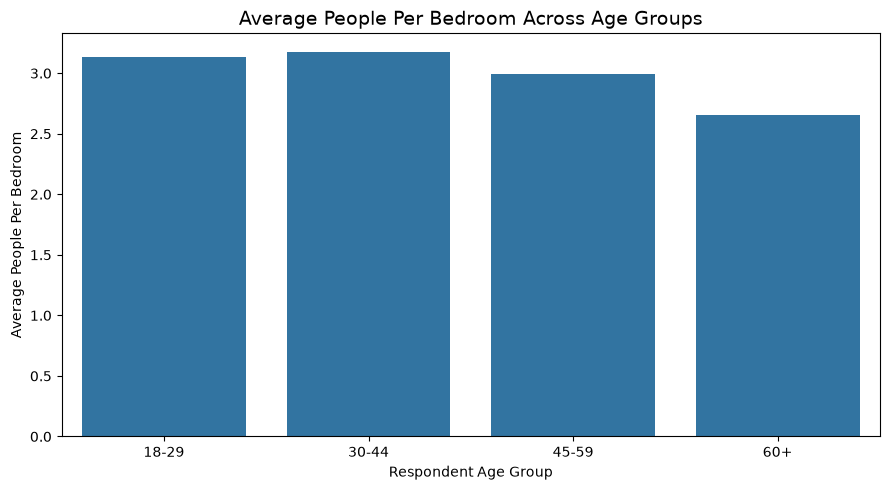

In [90]:
# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_bedroom_analysis.reset_index(),
    x="age_group",
    y="mean"
)

plt.title("Average People Per Bedroom Across Age Groups", fontsize=14)
plt.xlabel("Respondent Age Group")
plt.ylabel("Average People Per Bedroom")

plt.tight_layout()
plt.show()

### Key Findings

- Respondents aged 30–44 have the highest average people per bedroom (3.17).
- Respondents aged 18–29 have an average of 3.14 people per bedroom.
- The 45–59 age group has an average of 2.99.
- The 60+ age group has the lowest average of 2.66.
- The average number of people per bedroom generally decreases across the older respondent age groups.
- These findings describe associations and do not establish causation.

In [91]:
# Age Group vs Number of Bedrooms

age_bedrooms_analysis = df.groupby("age_group")[
    "bedrooms"
].agg(
    ["count", "mean", "median"]
)

age_bedrooms_analysis

,count,mean,median
age_group,,,
18-29,2969,1.906703,2.0
30-44,6078,1.884666,2.0
45-59,4237,2.030682,2.0
60+,1567,2.262285,2.0


### Key Findings

- Respondents aged 60+ have the highest average number of bedrooms (2.26).
- The 45–59 age group has an average of 2.03 bedrooms.
- The 18–29 age group has an average of 1.91 bedrooms.
- The 30–44 age group has the lowest average of 1.88 bedrooms.
- All age groups have a median of 2 bedrooms.
- The differences in average bedroom counts across age groups are relatively small.

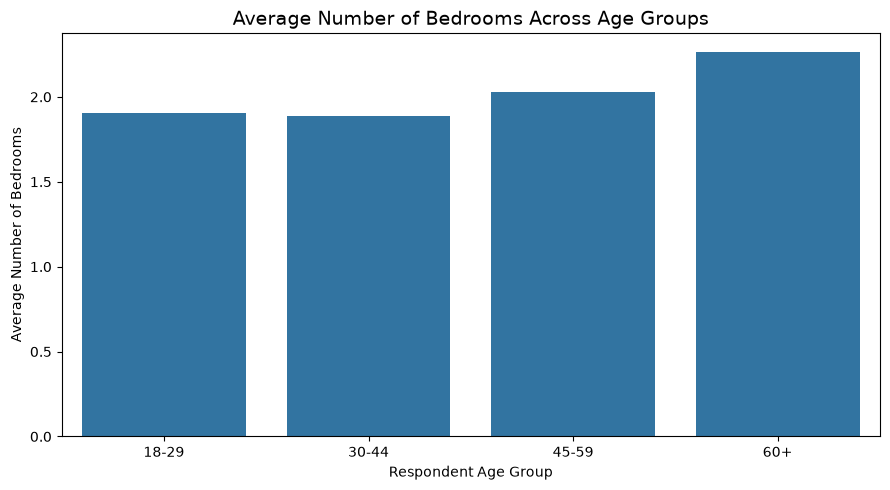

In [92]:
# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_bedrooms_analysis.reset_index(),
    x="age_group",
    y="mean"
)

plt.title("Average Number of Bedrooms Across Age Groups", fontsize=14)
plt.xlabel("Respondent Age Group")
plt.ylabel("Average Number of Bedrooms")

plt.tight_layout()
plt.show()

### Key Findings

- Respondents aged 60+ have the highest average number of bedrooms (2.26).
- The 45–59 age group has an average of 2.03 bedrooms.
- The 18–29 age group has an average of 1.91 bedrooms.
- The 30–44 age group has the lowest average of 1.88 bedrooms.
- All age groups have a median of 2 bedrooms.
- The differences in average bedroom counts across age groups are relatively small.

In [93]:
# Age Group vs Electricity Bill

age_bill_analysis = df.groupby("age_group")[
    "avg_monthly_elec_bill"
].agg(
    ["count", "mean", "median"]
)

age_bill_analysis

,count,mean,median
age_group,,,
18-29,2969,677.147173,500.00000
30-44,6078,693.768370,566.66669
45-59,4237,713.836888,566.66669
60+,1567,745.447327,650.00000


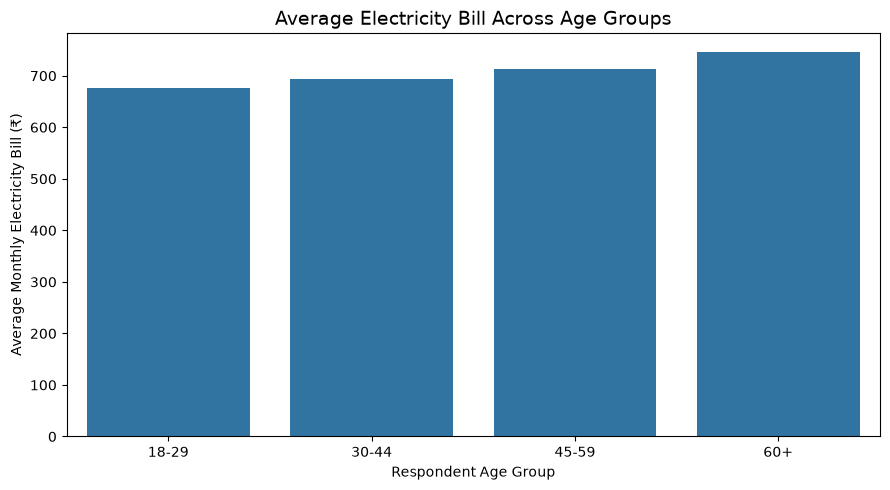

In [94]:
# visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_bill_analysis.reset_index(),
    x="age_group",
    y="mean"
)

plt.title("Average Electricity Bill Across Age Groups", fontsize=14)
plt.xlabel("Respondent Age Group")
plt.ylabel("Average Monthly Electricity Bill (₹)")

plt.tight_layout()
plt.show()

### Key Findings

- Respondents aged 60+ have the highest average electricity bill (₹745.45).
- The 45–59 age group has an average bill of ₹713.84.
- The 30–44 age group has an average bill of ₹693.77.
- The 18–29 age group has the lowest average bill of ₹677.15.
- Average electricity bills increase gradually across the respondent age groups.
- These findings describe an association and do not establish causation.

In [95]:
# Age Group vs Electricity Bill Per Member

age_bill_per_member = df.groupby("age_group")[
    "elec_bill_per_member"
].agg(
    ["count", "mean", "median"]
)

age_bill_per_member

,count,mean,median
age_group,,,
18-29,2969,160.615423,106.67
30-44,6078,158.529276,116.67
45-59,4237,172.167682,116.67
60+,1567,199.234052,133.33


### Key Findings

- Respondents aged 60+ have the highest average electricity bill per member (₹199.23).
- The 45–59 age group has an average of ₹172.17 per member.
- The 18–29 age group has an average of ₹160.62 per member.
- The 30–44 age group has the lowest average of ₹158.53 per member.
- The 60+ age group shows higher average per-member electricity expenses.
- These findings describe associations and do not establish causation.

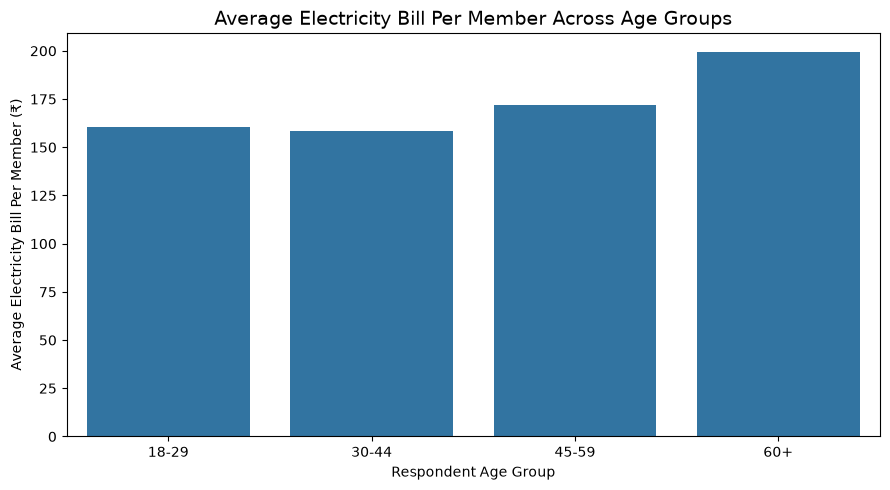

In [96]:
# visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_bill_per_member.reset_index(),
    x="age_group",
    y="mean"
)

plt.title("Average Electricity Bill Per Member Across Age Groups", fontsize=14)
plt.xlabel("Respondent Age Group")
plt.ylabel("Average Electricity Bill Per Member (₹)")

plt.tight_layout()
plt.show()

### Key Findings

- Respondents aged 60+ have the highest average electricity bill per member (₹199.23).
- The 45–59 age group has an average of ₹172.17 per member.
- The 18–29 age group has an average of ₹160.62 per member.
- The 30–44 age group has the lowest average of ₹158.53 per member.
- The 60+ age group shows higher average per-member electricity expenses.
- These findings describe associations and do not establish causation.

In [97]:
# Age Group vs Monthly Expenditure

age_expenditure_analysis = df.groupby("age_group")[
    "monthly_expenditure"
].agg(
    ["count", "mean", "median"]
)

age_expenditure_analysis

,count,mean,median
age_group,,,
18-29,2969,7988.279555,7000.0
30-44,6078,7888.678513,6500.0
45-59,4237,8081.704980,7000.0
60+,1567,7844.362476,6000.0


### Key Findings

- The 45–59 age group has the highest average monthly expenditure (₹8,081.70).
- The 18–29 age group has an average expenditure of ₹7,988.28.
- The 30–44 age group has an average expenditure of ₹7,888.68.
- The 60+ age group has the lowest average expenditure (₹7,844.36).
- Average monthly expenditure is relatively similar across all four age groups.
- Respondent age group shows only modest differences in average household expenditure.

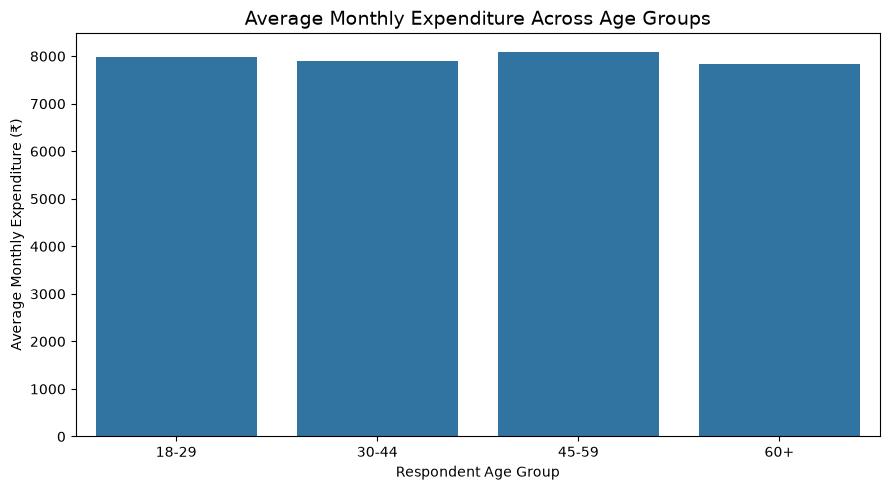

In [98]:
# visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_expenditure_analysis.reset_index(),
    x="age_group",
    y="mean"
)

plt.title("Average Monthly Expenditure Across Age Groups", fontsize=14)
plt.xlabel("Respondent Age Group")
plt.ylabel("Average Monthly Expenditure (₹)")

plt.tight_layout()
plt.show()

# Section 7 – Appliance Ownership and Electricity Bills

This section examines how selected household appliance ownership is associated with the average monthly electricity bill. The comparisons are descriptive only; they do not prove that owning an appliance causes a higher bill.

For the yes/no appliance indicators, `1` represents a recorded ownership/use response and `0` represents a recorded non-ownership/non-use response. Missing responses are kept separate and are not treated as `No`.

### 7.1 – Appliance Ownership Distribution

We will examine six appliance indicators available in the processed dataset: ceiling fan, air cooler, air conditioner, television, refrigerator and water pump.

In [99]:
# Select appliance ownership/use indicators available in the dataset
appliance_columns = {
    "Ceiling Fan": "q409_ceiling_fan_yn",
    "Air Cooler": "q421_air_coolers_yn",
    "Air Conditioner": "q427_ac_yn",
    "Television": "q459_tv_yn",
    "Refrigerator": "q466_fridge_yn",
    "Water Pump": "q477_water_pump_yn"
}

appliance_ownership_rows = []

for appliance, column in appliance_columns.items():
    if column not in df.columns:
        continue

    valid_responses = df[column].isin([0, 1])
    valid_count = int(valid_responses.sum())
    yes_count = int((df[column] == 1).sum())
    no_count = int((df[column] == 0).sum())
    missing_count = int(df[column].isna().sum())

    appliance_ownership_rows.append({
        "Appliance": appliance,
        "Yes": yes_count,
        "No": no_count,
        "Valid Responses": valid_count,
        "Missing Responses": missing_count,
        "Ownership (%)": (yes_count / valid_count * 100) if valid_count else np.nan
    })

appliance_ownership = (
    pd.DataFrame(appliance_ownership_rows)
    .sort_values("Ownership (%)", ascending=False)
    .set_index("Appliance")
)

appliance_ownership.round(2)

,Yes,No,Valid Responses,Missing Responses,Ownership (%)
Appliance,,,,,
Ceiling Fan,12954,1454,14408,443,89.91
Television,10513,3894,14407,444,72.97
Refrigerator,5254,9153,14407,444,36.47
Water Pump,1844,12563,14407,444,12.80
Air Cooler,1813,12594,14407,444,12.58
Air Conditioner,469,13927,14396,455,3.26


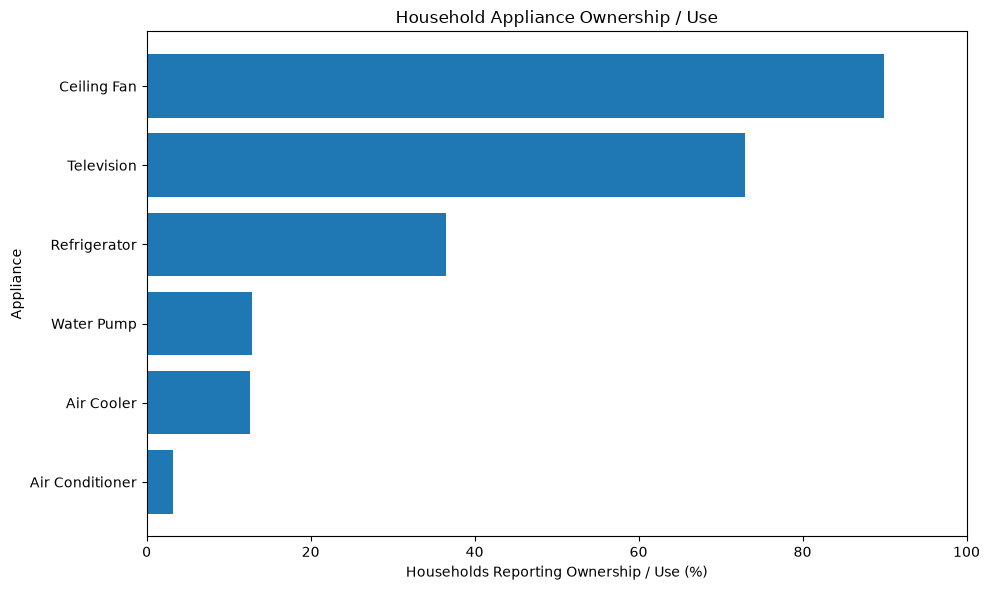

In [100]:
# Visualize the percentage of valid responses indicating appliance ownership/use
ownership_plot = appliance_ownership["Ownership (%)"].sort_values()

plt.figure(figsize=(10, 6))
plt.barh(ownership_plot.index, ownership_plot.values)
plt.title("Household Appliance Ownership / Use")
plt.xlabel("Households Reporting Ownership / Use (%)")
plt.ylabel("Appliance")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### 7.2 – Appliance Ownership vs Average Monthly Electricity Bill

Next, compare the average and median monthly electricity bill for households that reported each appliance and those that did not. Only valid `0` and `1` responses are included in each comparison.

In [101]:
appliance_bill_rows = []

for appliance, column in appliance_columns.items():
    if column not in df.columns:
        continue

    valid_data = df.loc[
        df[column].isin([0, 1]),
        [column, "avg_monthly_elec_bill"]
    ].dropna(subset=["avg_monthly_elec_bill"])

    for response_code, response_label in [(0, "No"), (1, "Yes")]:
        group = valid_data.loc[valid_data[column] == response_code, "avg_monthly_elec_bill"]
        if not group.empty:
            appliance_bill_rows.append({
                "Appliance": appliance,
                "Ownership": response_label,
                "Count": int(group.count()),
                "Mean Bill": group.mean(),
                "Median Bill": group.median()
            })

appliance_bill_analysis = pd.DataFrame(appliance_bill_rows)
appliance_bill_analysis.round(2)

,Appliance,Ownership,Count,Mean Bill,Median Bill
0,Ceiling Fan,No,1454,414.13,300.00
1,Ceiling Fan,Yes,12954,735.40,627.83
2,Air Cooler,No,12594,660.71,483.33
3,Air Cooler,Yes,1813,996.80,833.33
4,Air Conditioner,No,13927,676.31,533.33
5,Air Conditioner,Yes,469,1505.38,1400.00
6,Television,No,3894,528.94,333.33
7,Television,Yes,10513,767.48,660.00
8,Refrigerator,No,9153,569.84,390.00
9,Refrigerator,Yes,5254,934.99,833.33


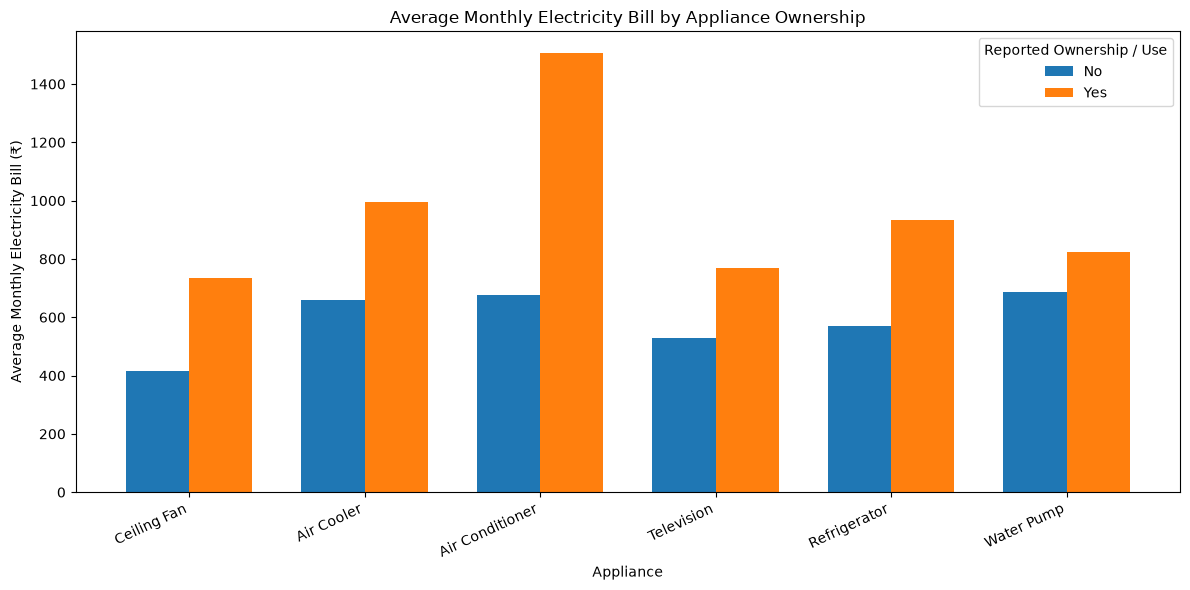

In [102]:
# Compare mean electricity bills for households reporting Yes vs No
appliance_plot = appliance_bill_analysis.pivot(
    index="Appliance",
    columns="Ownership",
    values="Mean Bill"
).reindex(appliance_columns.keys())

x = np.arange(len(appliance_plot.index))
bar_width = 0.36

plt.figure(figsize=(12, 6))
if "No" in appliance_plot.columns:
    plt.bar(x - bar_width / 2, appliance_plot["No"], bar_width, label="No")
if "Yes" in appliance_plot.columns:
    plt.bar(x + bar_width / 2, appliance_plot["Yes"], bar_width, label="Yes")

plt.title("Average Monthly Electricity Bill by Appliance Ownership")
plt.xlabel("Appliance")
plt.ylabel("Average Monthly Electricity Bill (₹)")
plt.xticks(x, appliance_plot.index, rotation=25, ha="right")
plt.legend(title="Reported Ownership / Use")
plt.tight_layout()
plt.show()

**Interpretation guide:** Identify which appliances have the highest reported ownership and which ownership groups show higher average bills. Treat these as associations. Differences may also reflect household size, income, region, climate and other factors.

# Section 8 – Seasonal Electricity Bill Analysis

The processed dataset contains reported electricity bills for three four-month periods. This section compares the reported bill amounts across those periods. These columns are components used in constructing the average monthly bill target, so they are useful for EDA but must not be used as predictors when that target is being modelled.

### 8.1 – Compare the Three Seasonal Bill Periods

In [103]:
seasonal_bill_columns = {
    "March–June": "q315_a_bill_mar_jun",
    "July–October": "q315_b_bill_jul_oct",
    "November–February": "q315_c_bill_nov_feb"
}

seasonal_bill_rows = []

for season, column in seasonal_bill_columns.items():
    if column not in df.columns:
        continue

    values = df[column].dropna()
    seasonal_bill_rows.append({
        "Period": season,
        "Valid Records": int(values.count()),
        "Mean Bill (₹)": values.mean(),
        "Median Bill (₹)": values.median(),
        "Minimum (₹)": values.min(),
        "Maximum (₹)": values.max()
    })

seasonal_bill_analysis = pd.DataFrame(seasonal_bill_rows).set_index("Period")
seasonal_bill_analysis.round(2)

,Valid Records,Mean Bill (₹),Median Bill (₹),Minimum (₹),Maximum (₹)
Period,,,,,
March–June,12183,1150.34,650.0,0.0,30000.0
July–October,12158,941.77,513.5,0.0,25000.0
November–February,12136,711.26,400.0,0.0,40000.0


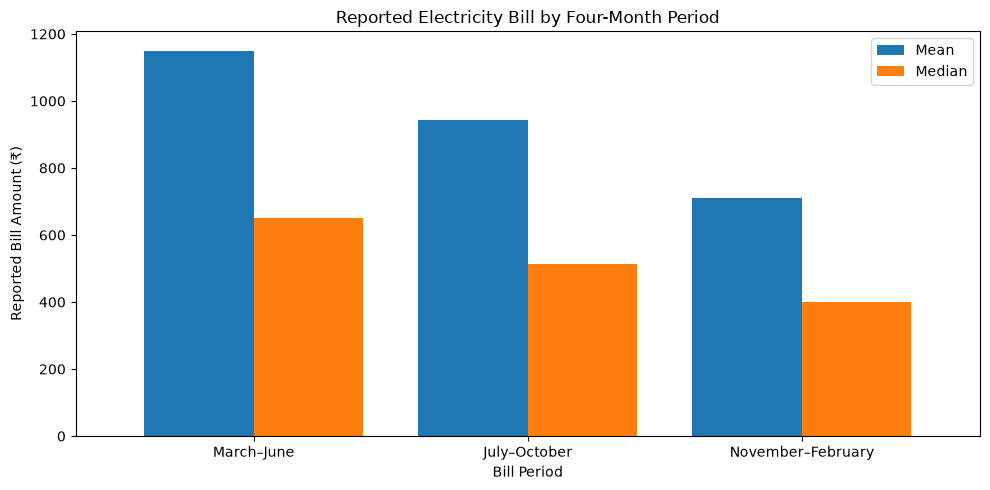

In [104]:
# Visualize mean and median reported bills across the three periods
seasonal_bill_analysis[["Mean Bill (₹)", "Median Bill (₹)"]].plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

plt.title("Reported Electricity Bill by Four-Month Period")
plt.xlabel("Bill Period")
plt.ylabel("Reported Bill Amount (₹)")
plt.xticks(rotation=0)
plt.legend(["Mean", "Median"])
plt.tight_layout()
plt.show()

### 8.2 – Compare Seasonal Bill Distributions

A boxplot helps compare the spread and median of the three bill distributions. The plot hides individual outlier markers to keep the central distributions readable; the original values are not removed from the dataset.

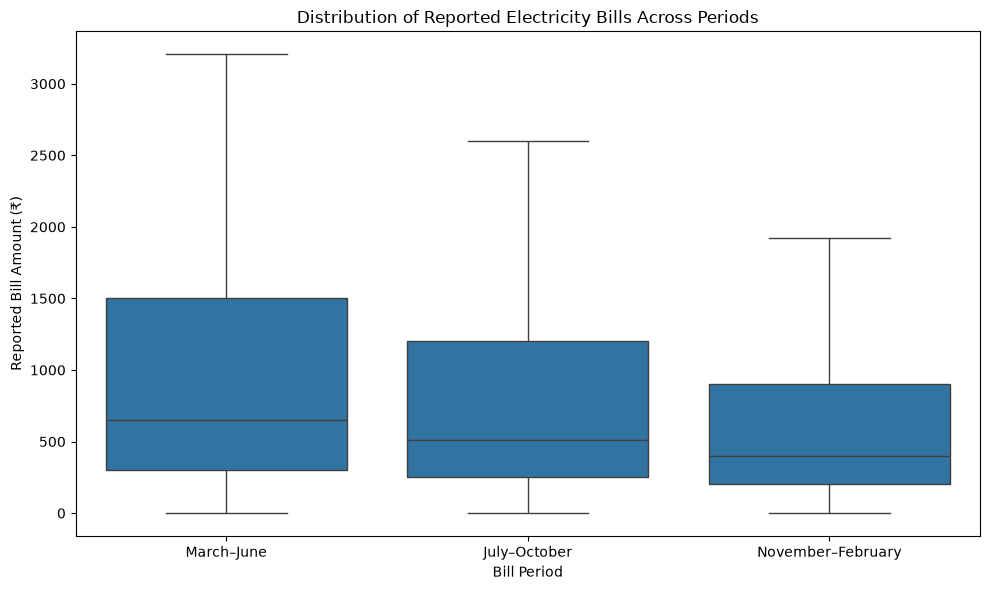

In [105]:
seasonal_bill_long = df[list(seasonal_bill_columns.values())].melt(
    var_name="Bill Period",
    value_name="Reported Bill (₹)"
).dropna()

season_label_map = {value: key for key, value in seasonal_bill_columns.items()}
seasonal_bill_long["Bill Period"] = seasonal_bill_long["Bill Period"].map(season_label_map)

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=seasonal_bill_long,
    x="Bill Period",
    y="Reported Bill (₹)",
    showfliers=False
)

plt.title("Distribution of Reported Electricity Bills Across Periods")
plt.xlabel("Bill Period")
plt.ylabel("Reported Bill Amount (₹)")
plt.tight_layout()
plt.show()

**Interpretation guide:** Compare the mean and median across periods and note whether one period tends to have higher reported bills. Remember that these are reported bill amounts for four-month periods, not direct electricity-consumption measurements in kWh.

# Section 9 – Electricity Bill Payment Pattern

This section examines the reported use of online payment for electricity bills and compares bill amounts by online-payment response. It is a household payment-behaviour analysis, not a measure of electricity consumption.

### 9.1 – Online Electricity Bill Payment

In [106]:
online_payment_column = "q314_pay_online_1"

if online_payment_column in df.columns:
    online_payment_data = df[online_payment_column].dropna()

    online_payment_summary = pd.DataFrame({
        "Response Count": online_payment_data.value_counts().sort_index(),
        "Percentage of Valid Responses": (
            online_payment_data.value_counts(normalize=True).sort_index() * 100
        )
    })
    online_payment_summary.index = online_payment_summary.index.map(
        {0: "No (code 0)", 1: "Yes (code 1)"}
    )
    online_payment_summary.round(2)
else:
    print(f"Column not found: {online_payment_column}")

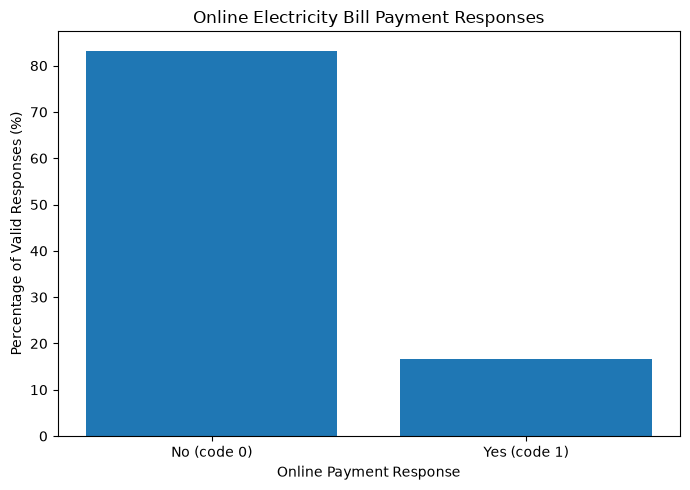

In [107]:
if online_payment_column in df.columns:
    online_payment_plot = (
        df[online_payment_column]
        .value_counts(normalize=True)
        .reindex([0, 1])
        .mul(100)
        .rename(index={0: "No (code 0)", 1: "Yes (code 1)"})
    )

    plt.figure(figsize=(7, 5))
    plt.bar(online_payment_plot.index, online_payment_plot.values)
    plt.title("Online Electricity Bill Payment Responses")
    plt.xlabel("Online Payment Response")
    plt.ylabel("Percentage of Valid Responses (%)")
    plt.tight_layout()
    plt.show()

### 9.2 – Online Payment Response vs Average Monthly Electricity Bill

The following comparison uses only valid online-payment responses (`0` or `1`). Missing values are excluded rather than recoded.

In [108]:
if online_payment_column in df.columns:
    online_bill_data = df.loc[
        df[online_payment_column].isin([0, 1]),
        [online_payment_column, "avg_monthly_elec_bill"]
    ].dropna()

    online_bill_analysis = (
        online_bill_data.groupby(online_payment_column)["avg_monthly_elec_bill"]
        .agg(["count", "mean", "median"])
        .rename(index={0: "No (code 0)", 1: "Yes (code 1)"})
        .rename(columns={"count": "Count", "mean": "Mean Bill (₹)", "median": "Median Bill (₹)"})
    )
    display(online_bill_analysis.round(2))
else:
    print(f"Column not found: {online_payment_column}")

,Count,Mean Bill (₹),Median Bill (₹)
q314_pay_online_1,,,
No (code 0),11939,669.61,500.00
Yes (code 1),2402,876.94,766.67


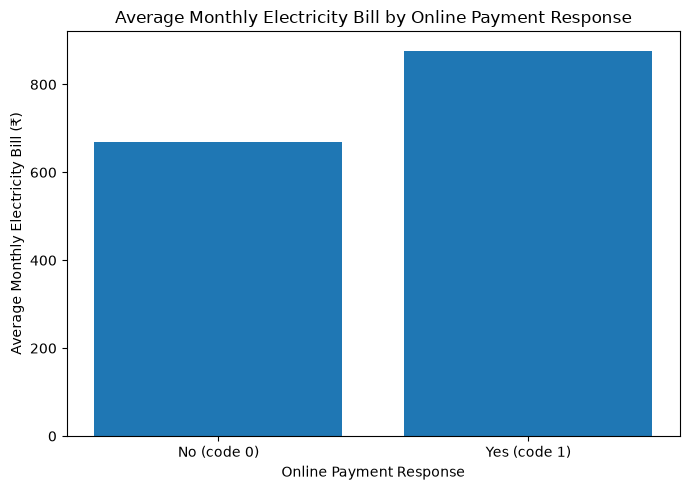

In [109]:
if online_payment_column in df.columns:
    online_bill_plot = online_bill_data.assign(
        Online_Payment=online_bill_data[online_payment_column].map(
            {0: "No (code 0)", 1: "Yes (code 1)"}
        )
    )
    mean_bill_by_payment = online_bill_plot.groupby("Online_Payment")["avg_monthly_elec_bill"].mean()
    mean_bill_by_payment = mean_bill_by_payment.reindex(["No (code 0)", "Yes (code 1)"])

    plt.figure(figsize=(7, 5))
    plt.bar(mean_bill_by_payment.index, mean_bill_by_payment.values)
    plt.title("Average Monthly Electricity Bill by Online Payment Response")
    plt.xlabel("Online Payment Response")
    plt.ylabel("Average Monthly Electricity Bill (₹)")
    plt.tight_layout()
    plt.show()

**Interpretation guide:** Report the share of valid responses for each online-payment category and compare the mean/median bill amounts. Do not conclude that online payment causes a higher or lower bill; the groups may differ in income, location, access and other characteristics.

# Section 10 – Final EDA Summary and Machine Learning Readiness

This final section checks the quality of the proposed prediction target and identifies columns that could create target leakage. It prepares the dataset for the next phase without training a model yet.

### 10.1 – Original vs Imputed Electricity Bill Target Values

The ETL output contains `avg_monthly_elec_bill` for every household, but `avg_monthly_elec_bill_was_missing` indicates whether the original bill information was missing before imputation. For a first supervised model, rows with originally observed target values should be used for training and evaluation so that the model is judged against reported, not imputed, target values.

In [110]:
target_column = "avg_monthly_elec_bill"
target_missing_flag = "avg_monthly_elec_bill_was_missing"

if target_column in df.columns and target_missing_flag in df.columns:
    target_quality_summary = (
        df.groupby(target_missing_flag)[target_column]
        .agg(["count", "mean", "median", "min", "max"])
        .rename(index={False: "Originally observed target", True: "Originally missing / imputed target"})
        .rename(columns={
            "count": "Households",
            "mean": "Mean Bill (₹)",
            "median": "Median Bill (₹)",
            "min": "Minimum (₹)",
            "max": "Maximum (₹)"
        })
    )

    display(target_quality_summary.round(2))

    observed_target_count = int((~df[target_missing_flag]).sum())
    imputed_target_count = int(df[target_missing_flag].sum())
    total_target_count = len(df)

    print(f"Total households: {total_target_count:,}")
    print(f"Originally observed target values: {observed_target_count:,} ({observed_target_count / total_target_count * 100:.2f}%)")
    print(f"Originally missing / imputed target values: {imputed_target_count:,} ({imputed_target_count / total_target_count * 100:.2f}%)")

,Households,Mean Bill (₹),Median Bill (₹),Minimum (₹),Maximum (₹)
avg_monthly_elec_bill_was_missing,,,,,
Originally observed target,9469,730.03,500.00,53.33,3381.87
Originally missing / imputed target,5382,651.65,716.67,133.33,1600.00


Total households: 14,851
Originally observed target values: 9,469 (63.76%)
Originally missing / imputed target values: 5,382 (36.24%)


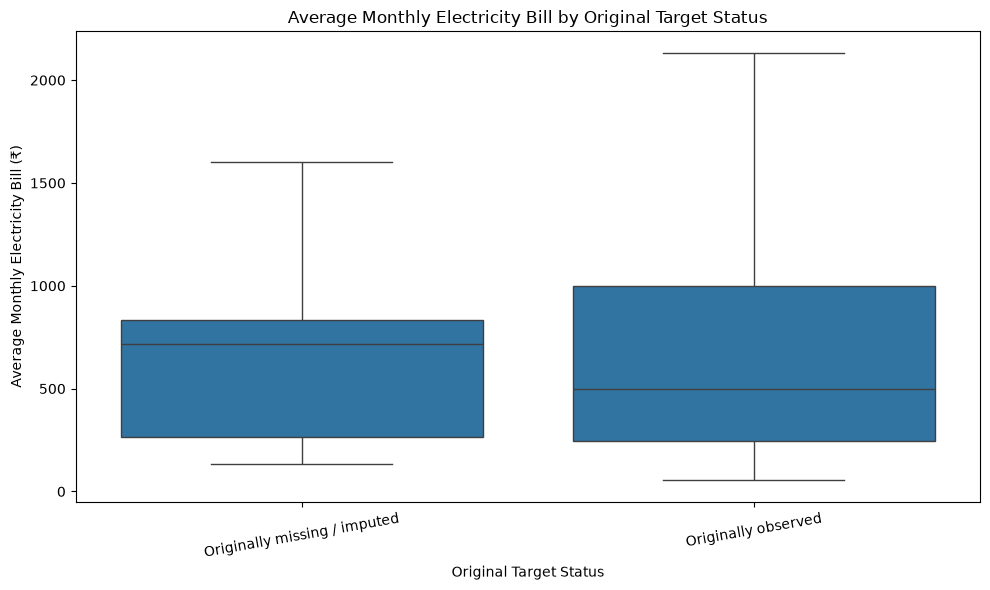

In [111]:
# Compare target distributions by original missingness status
if target_column in df.columns and target_missing_flag in df.columns:
    target_plot_data = df[[target_column, target_missing_flag]].copy()
    target_plot_data["Target Status"] = target_plot_data[target_missing_flag].map({
        False: "Originally observed",
        True: "Originally missing / imputed"
    })

    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=target_plot_data,
        x="Target Status",
        y=target_column,
        showfliers=False
    )
    plt.title("Average Monthly Electricity Bill by Original Target Status")
    plt.xlabel("Original Target Status")
    plt.ylabel("Average Monthly Electricity Bill (₹)")
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.show()

### 10.2 – Identify Potential Target-Leakage Columns

Target leakage occurs when a model receives information that directly contains, or is calculated from, the value it is supposed to predict. The following columns should be excluded from the first model for `avg_monthly_elec_bill`.

In [112]:
leakage_reasons = {
    "q315_a_bill_mar_jun": "Seasonal bill component used to construct the target.",
    "q315_b_bill_jul_oct": "Seasonal bill component used to construct the target.",
    "q315_c_bill_nov_feb": "Seasonal bill component used to construct the target.",
    "elec_bill_per_member": "Calculated using the target electricity bill.",
    "bill_share_of_expenditure_pct": "Calculated using the target electricity bill.",
    "bill_group": "Category derived from the target electricity bill.",
    "state_bill_rank": "Rank derived from electricity bill values.",
    "household_bill_rank": "Rank derived from electricity bill values.",
    "avg_monthly_elec_bill_was_missing": "Target-quality flag; using it can reveal whether the target was imputed.",
    "q610_c_billed_amount": "A billed amount that may overlap with the prediction target; exclude from the first baseline."
}

leakage_audit = pd.DataFrame([
    {
        "Column": column,
        "Present in Dataset": column in df.columns,
        "Reason for Exclusion": reason
    }
    for column, reason in leakage_reasons.items()
])

leakage_audit

,Column,Present in Dataset,Reason for Exclusion
0,q315_a_bill_mar_jun,True,Seasonal bill component used to construct the ...
1,q315_b_bill_jul_oct,True,Seasonal bill component used to construct the ...
2,q315_c_bill_nov_feb,True,Seasonal bill component used to construct the ...
3,elec_bill_per_member,True,Calculated using the target electricity bill.
4,bill_share_of_expenditure_pct,True,Calculated using the target electricity bill.
5,bill_group,True,Category derived from the target electricity b...
6,state_bill_rank,True,Rank derived from electricity bill values.
7,household_bill_rank,True,Rank derived from electricity bill values.
8,avg_monthly_elec_bill_was_missing,True,Target-quality flag; using it can reveal wheth...
9,q610_c_billed_amount,True,A billed amount that may overlap with the pred...


### 10.3 – Recommended ML Dataset Setup

For the first bill-prediction baseline:

- **Target:** `avg_monthly_elec_bill`.
- **Target rows:** use only records where `avg_monthly_elec_bill_was_missing == False`.
- **Exclude:** all columns listed in the target-leakage audit.
- **Potential predictors:** household size, respondent age, state, district, housing characteristics and appliance ownership/use indicators. Select only columns that exist in the dataset and handle missing values and categorical encoding inside the training pipeline.
- **Sensitivity check:** assess the model both with and without `monthly_expenditure`. It is associated with the bill and its exact relationship to the electricity-bill amount should be checked before deciding whether it is suitable as a predictor.

This dataset contains household survey and electricity-bill information. It does not contain household-level time-stamped meter readings in kWh. Therefore, the current target supports **electricity-bill prediction**, not direct kWh forecasting or ground-truth energy-waste classification.

In [113]:
# Create a clean modelling subset with originally observed target values only.
# This does not train a model; it prepares the rows for the ML phase.

if target_column in df.columns and target_missing_flag in df.columns:
    modelling_df = df.loc[~df[target_missing_flag]].copy()

    leakage_columns_present = [
        column for column in leakage_reasons
        if column in modelling_df.columns
    ]

    modelling_df = modelling_df.drop(columns=leakage_columns_present)

    print("Modelling subset prepared.")
    print("Rows with originally observed target:", modelling_df.shape[0])
    print("Columns after removing leakage variables:", modelling_df.shape[1])
    print("Target column retained:", target_column in modelling_df.columns)
    print("Target missing values:", modelling_df[target_column].isna().sum())

Modelling subset prepared.
Rows with originally observed target: 9469
Columns after removing leakage variables: 333
Target column retained: True
Target missing values: 0


## Final EDA Conclusions

Use the results generated above to write a short project-specific summary. The main conclusions to retain are:

1. The CEEW IRES dataset provides a broad cross-sectional view of Indian households, including household characteristics, appliance ownership, electricity access and reported electricity bills.
2. The analysis has explored household size, age, state, expenditure, housing conditions, appliance ownership, seasonal bill amounts and online bill-payment patterns.
3. The average monthly electricity bill is a usable prediction target only when its original missingness is handled transparently. The first supervised baseline should be evaluated on originally observed target values.
4. Bill components and features calculated from the bill must be excluded from predictors to prevent target leakage.
5. Findings from this survey describe associations, not causation. The dataset does not directly measure actual energy waste or provide time-stamped kWh readings.

**EDA phase complete.** The next phase can build a regression pipeline to predict the average monthly household electricity bill and evaluate it using MAE, RMSE and R². Do not describe R² as classification accuracy.